# ĐỒ ÁN TRÍ TUỆ NHÂN TẠO: PHÂN LOẠI KIỂU THẢM RỪNG TỪ DỮ LIỆU ĐỊA HÌNH
## Forest Cover Type Classification (UCI Dataset ID: 31)

**Mô tả**: Phân loại 7 kiểu thảm rừng ôn đới núi cao tại Rừng quốc gia Roosevelt (Colorado, Hoa Kỳ) bằng **Random Forest**, kết hợp **lấy mẫu phân tầng**, **kỹ thuật tạo đặc trưng sinh thái** và các thí nghiệm phân tích triệt tiêu (ablation) theo [KE_HOACH_THI_NGHIEM.md](../docs/02_ke_hoach_va_kien_truc/KE_HOACH_THI_NGHIEM.md). Thí nghiệm E6 của kế hoạch (leave-one-wilderness-out) không nằm trong notebook này: phạm vi đánh giá là dự đoán **bên trong 4 vùng nghiên cứu**.

**Dữ liệu**: 581.012 ô lưới 30 m × 30 m, 54 thuộc tính trắc địa và thổ nhưỡng, 7 lớp mục tiêu.

### Mục lục
| Bước | Nội dung | Thí nghiệm |
| :---: | :--- | :--- |
| 1 | Môi trường, cấu hình, hàm dùng chung | |
| 2 | Nạp và thẩm tra dữ liệu | |
| 3 | Phân tích khám phá (EDA) | |
| 4 | Phân chia dữ liệu và mẫu khảo sát 15% | |
| 5 | Hàm tạo đặc trưng sinh thái | |
| 6 | Thí nghiệm trên mẫu khảo sát: trọng số lớp, đặc trưng, thổ nhưỡng | E0, E1, E2, E3 |
| 7 | Quy mô dữ liệu huấn luyện | E4 |
| 8 | Tinh chỉnh siêu tham số; ablation cột `Wilderness_Area` và tổ hợp khoảng cách; kiểm tra độ vững của E2/E3 | E5 |
| 9 | Mô hình cuối: huấn luyện, chốt số cây, lưu | |
| 10 | Đánh giá một lần trên D_final | |
| 11 | Tổng kết, hạn chế, đầu vào cho Bước trích xuất luật | |

**Quy tắc ra quyết định dùng xuyên suốt** (mục 2.2 và 5 của kế hoạch thí nghiệm):
1. Mọi so sánh cấu hình dùng **D_val**, lặp **3 seed**, báo cáo trung bình ± độ lệch chuẩn (SD).
2. Chênh lệch nhỏ hơn 1 SD của cấu hình tốt nhất được coi là **không khác biệt có ý nghĩa**; khi đó chọn cấu hình **đơn giản hơn** (ít cột hơn, hoặc ít nút hơn).
3. **D_final** chỉ dùng **một lần**, sau khi đã chốt toàn bộ cấu hình.

---
# BƯỚC 1: MÔI TRƯỜNG, CẤU HÌNH VÀ HÀM DÙNG CHUNG

In [1]:
# === THƯ VIỆN ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from IPython.display import display
import warnings, time, os, sys, gc, json
import psutil
import joblib
from scipy.stats import chi2

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, f1_score, precision_recall_fscore_support)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams.update({'figure.figsize': (12, 6), 'figure.dpi': 100, 'font.size': 11,
                     'axes.titlesize': 13, 'axes.labelsize': 12})
sns.set_theme(style='whitegrid', palette='deep')

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | Matplotlib {plt.matplotlib.__version__} | seaborn {sns.__version__}")
print(f"CPU: {os.cpu_count()} lõi | RAM: {psutil.virtual_memory().total / 2**30:.1f} GB")

Python 3.13.5 | NumPy 2.5.4 | pandas 3.1.1 | scikit-learn 1.9.1 | Matplotlib 3.11.2 | seaborn 0.13.2
CPU: 24 lõi | RAM: 15.8 GB


In [2]:
# === CẤU HÌNH THÍ NGHIỆM ===
RANDOM_STATE = 42
SEEDS = [42, 7, 2024]        # 3 seed cho mọi so sánh cấu hình
EVAL_FRACTION = 0.20         # D_final và D_val, mỗi tập 20% toàn bộ dữ liệu
EXPLORE_FRACTION = 0.15      # mẫu khảo sát (Bước 6): 15% toàn bộ dữ liệu, rút phân tầng từ D_pool
N_EST_EXP = 100              # số cây trong các thí nghiệm so sánh
N_EST_MAX = 300              # số cây tối đa của mô hình cuối (Bước 9)
MEM_BUDGET_GB = 3.0          # ngân sách bộ nhớ cho mô hình cuối
BYTES_PER_NODE = 64 + 7 * 8  # ước lượng: struct Node của sklearn + mảng value (7 lớp, float64)
np.random.seed(RANDOM_STATE)

CLASS_NAMES = {1: 'Spruce/Fir', 2: 'Lodgepole Pine', 3: 'Ponderosa Pine', 4: 'Cottonwood/Willow',
               5: 'Aspen', 6: 'Douglas-fir', 7: 'Krummholz'}
SHORT_NAMES = ['Spruce/\nFir', 'Lodgepole\nPine', 'Ponderosa\nPine', 'Cotton./\nWillow',
               'Aspen', 'Douglas-\nfir', 'Krumm-\nholz']
TARGET_NAMES = [f"Lớp {i} ({CLASS_NAMES[i]})" for i in range(1, 8)]
WA_NAMES = {1: 'Rawah', 2: 'Neota', 3: 'Comanche Peak', 4: 'Cache la Poudre'}


# === ĐƯỜNG DẪN DỰ ÁN ===
# Notebook nằm trong notebooks/. Tìm thư mục gốc (chứa docs/ và notebooks/) để chạy được
# từ gốc dự án, từ notebooks/, hoặc trên Colab sau khi clone repo.
def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'docs').is_dir() and (p / 'notebooks').is_dir():
            return p
    return start


PROJECT_ROOT = _find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / 'data' / 'raw'
MODEL_DIR = PROJECT_ROOT / 'models'
FIG_DIR = PROJECT_ROOT / 'results' / 'figures'
TABLE_DIR = PROJECT_ROOT / 'results' / 'tables'
for _d in (DATA_DIR, MODEL_DIR, FIG_DIR, TABLE_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print(f"Thư mục dự án: {PROJECT_ROOT}")

Thư mục dự án: D:\Git_Repo\Forest Cover Type Classification


In [3]:
# === HÀM DÙNG CHUNG ===
def wilson_ci(k, n, z=1.96):
    """Khoảng tin cậy Wilson 95% cho tỷ lệ k/n."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return (max(0.0, center - margin), min(1.0, center + margin))


def eval_preds(y_true, y_pred):
    """Accuracy, Macro-F1 và Precision / Recall / F1 của cả 7 lớp
    (khoá: precision_c1..c7, recall_c1..c7, f1_c1..c7)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=range(1, 8),
                                                       average=None, zero_division=0)
    out = {'accuracy': accuracy_score(y_true, y_pred),
           'macro_f1': f1_score(y_true, y_pred, average='macro')}
    for c in range(1, 8):
        out[f'precision_c{c}'] = prec[c - 1]
        out[f'recall_c{c}'] = rec[c - 1]
        out[f'f1_c{c}'] = f1[c - 1]
    return out


def n_nodes(rf):
    return int(sum(e.tree_.node_count for e in rf.estimators_))


def rss_gb():
    return psutil.Process().memory_info().rss / 2**30


def fit_eval(X_tr, y_tr, X_ev, y_ev, params, seed):
    """Huấn luyện một RF, đánh giá trên tập so sánh, giải phóng mô hình."""
    rf = RandomForestClassifier(random_state=seed, n_jobs=-1, **params)
    t0 = time.time()
    rf.fit(X_tr, y_tr)
    row = {'seed': seed, 'n_train': len(y_tr), 'n_features': X_tr.shape[1],
           'fit_s': time.time() - t0, **eval_preds(y_ev, rf.predict(X_ev)), 'nodes': n_nodes(rf)}
    del rf
    gc.collect()
    return row


def summarize(df, by):
    """Trung bình ± SD qua các seed."""
    return (df.groupby(by, sort=False)
            .agg(n_features=('n_features', 'first'), n_train=('n_train', 'first'),
                 f1_mean=('macro_f1', 'mean'), f1_sd=('macro_f1', 'std'),
                 acc_mean=('accuracy', 'mean'),
                 rc4_mean=('recall_c4', 'mean'), rc4_sd=('recall_c4', 'std'), prec_c4=('precision_c4', 'mean'),
                 nodes=('nodes', 'mean'), fit_s=('fit_s', 'mean'))
            .reset_index())


def per_class_table(df, by, metric='f1'):
    """Bảng `metric` (f1 | precision | recall) của cả 7 lớp, trung bình qua các seed.
    Cột 'min' cho biết lớp yếu nhất của mỗi cấu hình."""
    cols = [f'{metric}_c{c}' for c in range(1, 8)]
    t = df.groupby(by, sort=False)[cols].mean()
    t.columns = [f'L{c}' for c in range(1, 8)]
    t['min'] = t.min(axis=1)
    return t


def show_per_class(df, by, title=''):
    """Hiển thị F1 từng lớp; Precision và Recall từng lớp nằm trong CSV."""
    print(f"--- F1 từng lớp (TB qua seed){': ' + title if title else ''} ---")
    display(per_class_table(df, by, 'f1').round(4))


def choose_simplest(summary, key, simplicity):
    """Quy tắc ra quyết định: trong các cấu hình có F1 TB ≥ (F1 tốt nhất − 1 SD), chọn cấu hình
    có giá trị `simplicity` nhỏ nhất (ít cột / ít nút). In ra lập luận và trả về hàng được chọn."""
    best = summary.loc[summary['f1_mean'].idxmax()]
    thr = best['f1_mean'] - best['f1_sd']
    cand = summary[summary['f1_mean'] >= thr].sort_values([simplicity, 'f1_mean'], ascending=[True, False])
    chosen = cand.iloc[0]
    print(f"Tốt nhất theo F1: {best[key]} ({best['f1_mean']:.4f} ± {best['f1_sd']:.4f}) → ngưỡng {thr:.4f}")
    print(f"Ứng viên trong ngưỡng: {cand[key].tolist()}")
    print(f"→ Chọn (ít {simplicity} nhất): {chosen[key]}  (F1 = {chosen['f1_mean']:.4f} ± {chosen['f1_sd']:.4f})")
    return chosen


print("✓ Đã khai báo hàm dùng chung.")

✓ Đã khai báo hàm dùng chung.


---
# BƯỚC 2: NẠP VÀ THẨM TRA DỮ LIỆU
> Thứ tự nguồn: `data/raw/covtype.data` → `data/raw/covtype.data.gz` → `sklearn.datasets.fetch_covtype()`. Bản tải qua scikit-learn đã được đối chiếu và trùng khớp từng giá trị, cùng thứ tự dòng với file UCI, nên các phép chia theo `random_state` cho cùng kết quả.

In [4]:
RAW_FEATURES = ['Elevation', 'Aspect', 'Slope',
                'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology',
                'Horizontal_Distance_To_Roadways',
                'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
                'Horizontal_Distance_To_Fire_Points'] \
               + [f'Wilderness_Area_{i}' for i in range(1, 5)] \
               + [f'Soil_Type_{i}' for i in range(1, 41)]
COL_NAMES = RAW_FEATURES + ['Cover_Type']

DATA_PATH, GZ_PATH = DATA_DIR / 'covtype.data', DATA_DIR / 'covtype.data.gz'
if DATA_PATH.exists():
    print(f"Đọc dữ liệu từ: {DATA_PATH}")
    df_raw = pd.read_csv(DATA_PATH, header=None, names=COL_NAMES)
elif GZ_PATH.exists():
    print(f"Đọc dữ liệu từ: {GZ_PATH}")
    df_raw = pd.read_csv(GZ_PATH, header=None, names=COL_NAMES, compression='gzip')
else:
    from sklearn.datasets import fetch_covtype
    print("Không thấy file cục bộ → tải UCI Covertype qua sklearn.datasets.fetch_covtype()")
    _cov = fetch_covtype(as_frame=False)
    df_raw = pd.DataFrame(np.column_stack([_cov.data, _cov.target]).astype(np.int64), columns=COL_NAMES)
print(f"Kích thước: {df_raw.shape[0]:,} dòng × {df_raw.shape[1]} cột")

Đọc dữ liệu từ: D:\Git_Repo\Forest Cover Type Classification\data\raw\covtype.data
Kích thước: 581,012 dòng × 55 cột


In [5]:
# === THẨM TRA TOÀN VẸN ===
EXPECTED_COUNTS = {1: 211840, 2: 283301, 3: 35754, 4: 2747, 5: 9493, 6: 17367, 7: 20510}
assert df_raw.shape == (581012, 55), f"Kích thước {df_raw.shape} ≠ (581012, 55)"
assert df_raw.isnull().sum().sum() == 0, "Có giá trị thiếu"
counts = df_raw['Cover_Type'].value_counts().sort_index()
assert counts.to_dict() == EXPECTED_COUNTS, "Phân bố lớp không khớp covtype.info"
assert (df_raw[[f'Wilderness_Area_{i}' for i in range(1, 5)]].sum(axis=1) == 1).all(), "Wilderness one-hot lỗi"
assert (df_raw[[f'Soil_Type_{i}' for i in range(1, 41)]].sum(axis=1) == 1).all(), "Soil one-hot lỗi"
print("✓ 581.012 × 55, 0 giá trị thiếu, phân bố 7 lớp khớp covtype.info, one-hot Wilderness/Soil hợp lệ.")

# === ÉP KIỂU ĐỂ GIẢM RAM ===
mem_before = df_raw.memory_usage(deep=True).sum() / 2**20
binary_cols = [c for c in RAW_FEATURES if c.startswith(('Wilderness_Area', 'Soil_Type'))]
df_raw[binary_cols] = df_raw[binary_cols].astype(np.uint8)
df_raw['Cover_Type'] = df_raw['Cover_Type'].astype(np.uint8)
numeric_cols = [c for c in RAW_FEATURES if c not in binary_cols]
df_raw[numeric_cols] = df_raw[numeric_cols].astype(np.int32)
print(f"RAM DataFrame: {mem_before:.1f} MB → {df_raw.memory_usage(deep=True).sum() / 2**20:.1f} MB")

# Mã vùng hoang dã (chỉ dùng cho EDA, không đưa vào mô hình)
wa_code = pd.Series(df_raw[[f'Wilderness_Area_{i}' for i in range(1, 5)]].values.argmax(axis=1) + 1,
                    index=df_raw.index, name='Wilderness')

✓ 581.012 × 55, 0 giá trị thiếu, phân bố 7 lớp khớp covtype.info, one-hot Wilderness/Soil hợp lệ.
RAM DataFrame: 243.8 MB → 47.1 MB


---
# BƯỚC 3: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)
> Mục tiêu: định lượng mất cân bằng lớp, đối chiếu phân bố cao độ với các đai sinh thái trong văn liệu (Peet 1981, Marr 1961), nêu giả định về quy ước dấu của `Vertical_Distance_To_Hydrology`, khảo sát tương quan và phân bố lớp theo vùng hoang dã.

## 3.1. Phân bố 7 kiểu thảm rừng và mức độ mất cân bằng

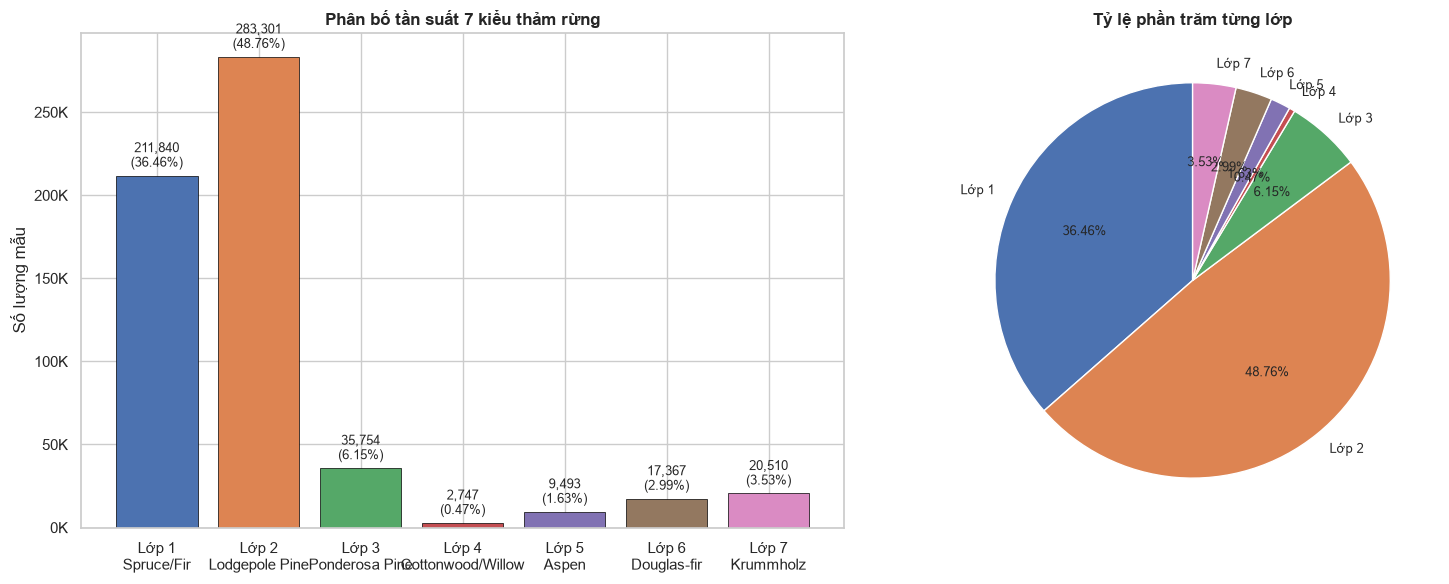

Hai lớp đa số (1+2): 495,141 mẫu (85.22%)
Lớp thiểu số (4):    2,747 mẫu (0.473%)
Tỷ số đa số / thiểu số: 180 : 1


In [6]:
class_counts = df_raw['Cover_Type'].value_counts().sort_index()
colors = sns.color_palette('deep', 7)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
bars = axes[0].bar([f"Lớp {i}\n{CLASS_NAMES[i]}" for i in range(1, 8)], class_counts.values,
                   color=colors, edgecolor='black', linewidth=0.5)
for bar, cnt in zip(bars, class_counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3000,
                 f'{cnt:,}\n({cnt / len(df_raw) * 100:.2f}%)', ha='center', va='bottom', fontsize=9)
axes[0].set_title('Phân bố tần suất 7 kiểu thảm rừng', fontweight='bold')
axes[0].set_ylabel('Số lượng mẫu')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x / 1000:.0f}K'))
axes[1].pie(class_counts.values, labels=[f"Lớp {i}" for i in range(1, 8)], autopct='%1.2f%%',
            colors=colors, startangle=90, textprops={'fontsize': 9})
axes[1].set_title('Tỷ lệ phần trăm từng lớp', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

majority, minority = class_counts[1] + class_counts[2], class_counts[4]
print(f"Hai lớp đa số (1+2): {majority:,} mẫu ({majority / len(df_raw) * 100:.2f}%)")
print(f"Lớp thiểu số (4):    {minority:,} mẫu ({minority / len(df_raw) * 100:.3f}%)")
print(f"Tỷ số đa số / thiểu số: {majority / minority:.0f} : 1")

## 3.2. Phân bố cao độ theo kiểu rừng — đối chiếu đai sinh thái

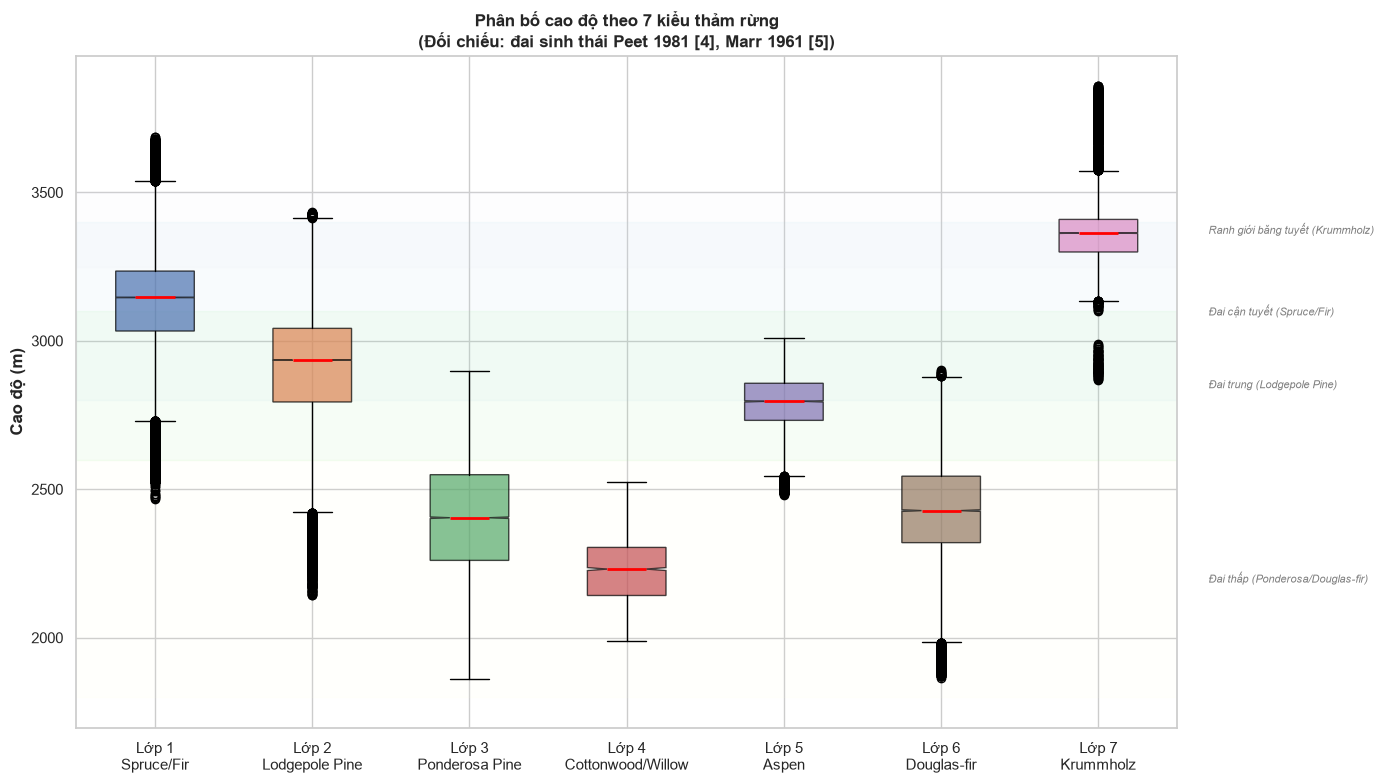

,mean,std,min,25%,50%,75%,max
Lớp 1 (Spruce/Fir),3128.6449,157.8055,2466.0000,3033.0000,3146.0000,3235.0000,3686.0000
Lớp 2 (Lodgepole Pine),2920.9361,186.5794,2142.0000,2794.0000,2935.0000,3042.0000,3433.0000
Lớp 3 (Ponderosa Pine),2394.5098,196.7324,1859.0000,2260.2500,2404.0000,2549.0000,2899.0000
Lớp 4 (Cottonwood/Willow),2223.9399,102.5246,1988.0000,2142.0000,2231.0000,2304.0000,2526.0000
Lớp 5 (Aspen),2787.4176,96.5940,2482.0000,2732.0000,2796.0000,2857.0000,3011.0000
Lớp 6 (Douglas-fir),2419.1819,188.7623,1863.0000,2320.0000,2428.0000,2544.0000,2900.0000
Lớp 7 (Krummholz),3361.9287,106.9153,2868.0000,3299.2500,3363.0000,3409.0000,3858.0000


In [7]:
fig, ax = plt.subplots(figsize=(14, 8))
bp = ax.boxplot([df_raw.loc[df_raw['Cover_Type'] == i, 'Elevation'].values for i in range(1, 8)],
                tick_labels=[f"Lớp {i}\n{CLASS_NAMES[i]}" for i in range(1, 8)],
                patch_artist=True, notch=True, medianprops=dict(color='red', linewidth=2))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for ymin, ymax, label, fcolor in [(1800, 2600, 'Đai thấp (Ponderosa/Douglas-fir)', 'lightyellow'),
                                  (2600, 3100, 'Đai trung (Lodgepole Pine)', 'lightgreen'),
                                  (2800, 3400, 'Đai cận tuyết (Spruce/Fir)', 'lightblue'),
                                  (3250, 3500, 'Ranh giới băng tuyết (Krummholz)', 'lavender')]:
    ax.axhspan(ymin, ymax, alpha=0.08, color=fcolor)
    ax.text(7.7, (ymin + ymax) / 2, label, fontsize=8, va='center', fontstyle='italic', color='gray')
ax.set_ylabel('Cao độ (m)', fontweight='bold')
ax.set_title('Phân bố cao độ theo 7 kiểu thảm rừng\n(Đối chiếu: đai sinh thái Peet 1981 [4], Marr 1961 [5])',
             fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_elevation_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

elev_stats = df_raw.groupby('Cover_Type')['Elevation'].describe()
elev_stats.index = TARGET_NAMES
display(elev_stats[['mean', 'std', 'min', '25%', '50%', '75%', 'max']])

## 3.3. Quy ước dấu của `Vertical_Distance_To_Hydrology`
> `covtype.info` chỉ mô tả biến này là khoảng cách đứng tới nguồn nước mặt gần nhất, không nêu quy ước dấu. Diễn giải dưới đây là **giả định**; biểu đồ chỉ minh hoạ hệ quả của giả định, không kiểm chứng được nó.

Min -173 | Max 601 | TB 46.42 | Trung vị 30.0
  Số mẫu < 0: 55,143 (9.5%)
  Số mẫu = 0: 38,665 (6.7%)
  Số mẫu > 0: 487,204 (83.9%)


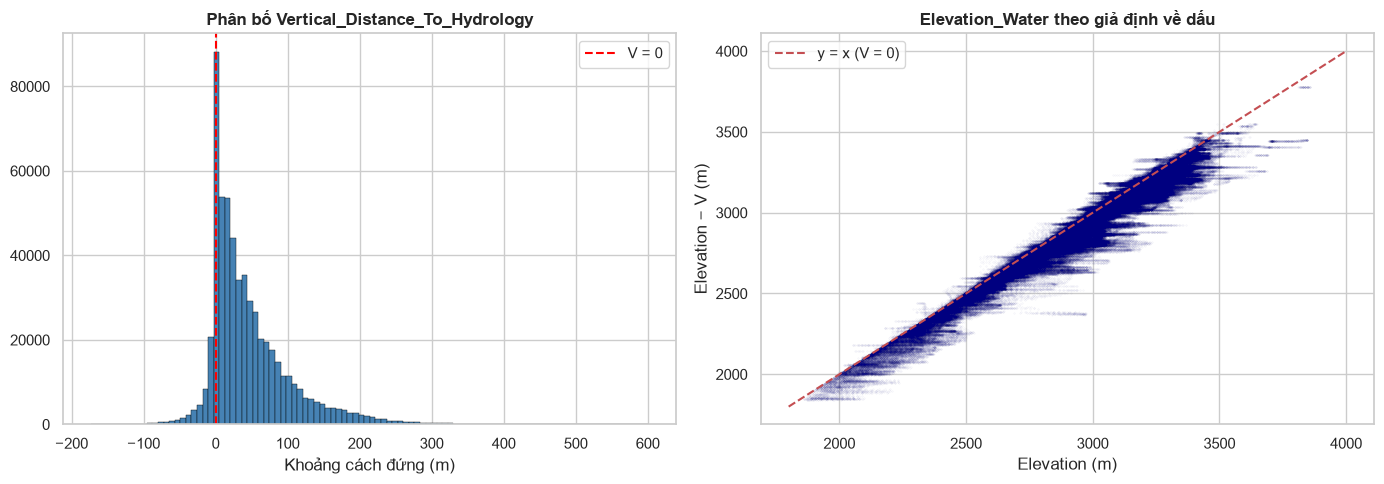

Giả định: V > 0 ⟹ điểm đo cao hơn nguồn nước (trên sườn); V < 0 ⟹ thấp hơn nguồn nước.
Theo giả định này, Elevation_Water = Elevation − V là cao độ của nguồn nước mặt gần nhất.


In [8]:
vdth = df_raw['Vertical_Distance_To_Hydrology']
print(f"Min {vdth.min()} | Max {vdth.max()} | TB {vdth.mean():.2f} | Trung vị {vdth.median():.1f}")
for lbl, mask in [('< 0', vdth < 0), ('= 0', vdth == 0), ('> 0', vdth > 0)]:
    print(f"  Số mẫu {lbl}: {mask.sum():,} ({mask.mean() * 100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(vdth, bins=100, edgecolor='black', linewidth=0.3, color='steelblue')
axes[0].axvline(0, color='red', linestyle='--', label='V = 0')
axes[0].set_title('Phân bố Vertical_Distance_To_Hydrology', fontweight='bold')
axes[0].set_xlabel('Khoảng cách đứng (m)')
axes[0].legend()
axes[1].scatter(df_raw['Elevation'], df_raw['Elevation'] - vdth, s=0.05, alpha=0.1, c='navy')
axes[1].plot([1800, 4000], [1800, 4000], 'r--', label='y = x (V = 0)')
axes[1].set_xlabel('Elevation (m)')
axes[1].set_ylabel('Elevation − V (m)')
axes[1].set_title('Elevation_Water theo giả định về dấu', fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_vertical_distance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Giả định: V > 0 ⟹ điểm đo cao hơn nguồn nước (trên sườn); V < 0 ⟹ thấp hơn nguồn nước.")
print("Theo giả định này, Elevation_Water = Elevation − V là cao độ của nguồn nước mặt gần nhất.")

## 3.4. Tương quan giữa các biến trắc địa liên tục

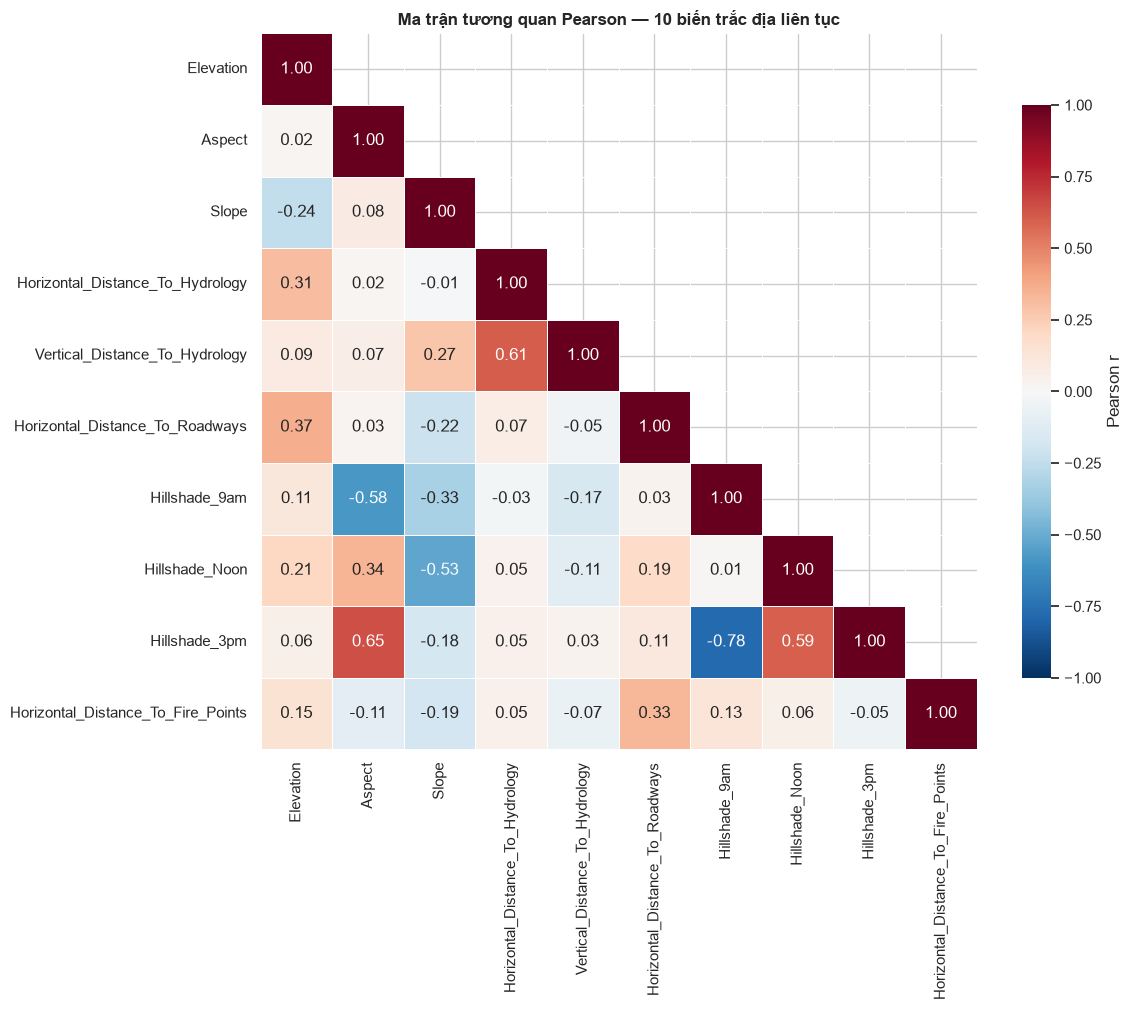

Các cặp |r| > 0,5:
                                Aspect ↔ Hillshade_9am                        r = -0.579
                                Aspect ↔ Hillshade_3pm                        r = +0.647
                                 Slope ↔ Hillshade_Noon                       r = -0.527
      Horizontal_Distance_To_Hydrology ↔ Vertical_Distance_To_Hydrology       r = +0.606
                         Hillshade_9am ↔ Hillshade_3pm                        r = -0.780
                        Hillshade_Noon ↔ Hillshade_3pm                        r = +0.594


In [9]:
continuous_cols = RAW_FEATURES[:10]
corr = df_raw[continuous_cols].corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax,
            cbar_kws={'shrink': 0.8, 'label': 'Pearson r'})
ax.set_title('Ma trận tương quan Pearson — 10 biến trắc địa liên tục', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Các cặp |r| > 0,5:")
for i in range(len(continuous_cols)):
    for j in range(i + 1, len(continuous_cols)):
        if abs(corr.iloc[i, j]) > 0.5:
            print(f"  {continuous_cols[i]:>36s} ↔ {continuous_cols[j]:<36s} r = {corr.iloc[i, j]:+.3f}")

## 3.5. Phân bố kiểu rừng theo vùng hoang dã (Wilderness Area)

Wilderness,WA1 (Rawah),WA2 (Neota),WA3 (Comanche Peak),WA4 (Cache la Poudre),Tổng
Cover_Type,,,,,
Lớp 1 (Spruce/Fir),105717,18595,87528,0,211840
Lớp 2 (Lodgepole Pine),146197,8985,125093,3026,283301
Lớp 3 (Ponderosa Pine),0,0,14300,21454,35754
Lớp 4 (Cottonwood/Willow),0,0,0,2747,2747
Lớp 5 (Aspen),3781,0,5712,0,9493
Lớp 6 (Douglas-fir),0,0,7626,9741,17367
Lớp 7 (Krummholz),5101,2304,13105,0,20510
Tổng,260796,29884,253364,36968,581012


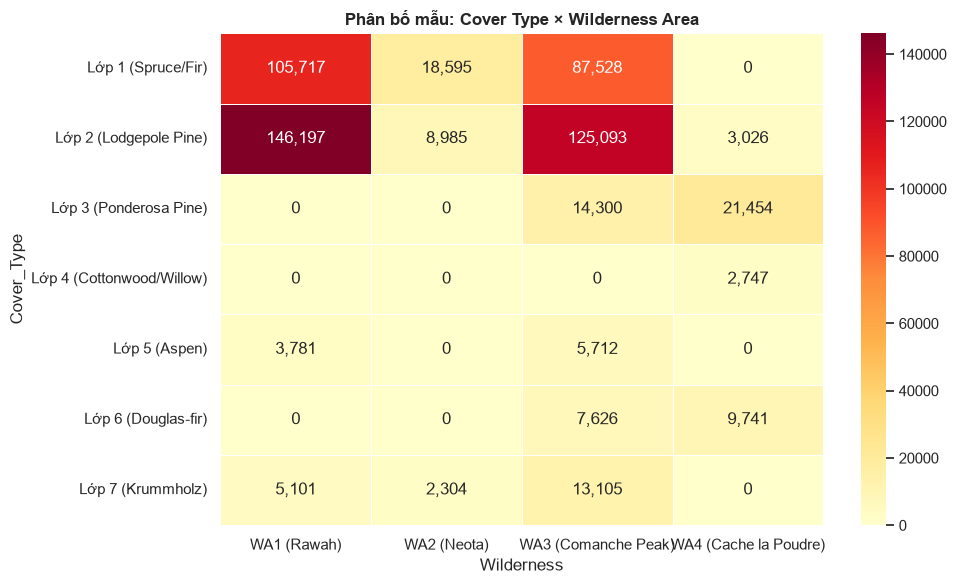

Các vùng có mặt từng lớp: {1: [np.int64(1), np.int64(2), np.int64(3)], 2: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)], 3: [np.int64(3), np.int64(4)], 4: [np.int64(4)], 5: [np.int64(1), np.int64(3)], 6: [np.int64(3), np.int64(4)], 7: [np.int64(1), np.int64(2), np.int64(3)]}


In [10]:
ct = pd.crosstab(df_raw['Cover_Type'].map(lambda x: f"Lớp {x} ({CLASS_NAMES[x]})"),
                 wa_code.map(lambda x: f"WA{x} ({WA_NAMES[x]})"), margins=True, margins_name='Tổng')
display(ct)
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(ct.iloc[:-1, :-1].astype(int), annot=True, fmt=',', cmap='YlOrRd', ax=ax, linewidths=0.5)
ax.set_title('Phân bố mẫu: Cover Type × Wilderness Area', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_crosstab_wa.png', dpi=150, bbox_inches='tight')
plt.show()
only_in = {c: sorted(wa_code[df_raw['Cover_Type'] == c].unique()) for c in range(1, 8)}
print("Các vùng có mặt từng lớp:", {c: v for c, v in only_in.items()})

---
# BƯỚC 4: PHÂN CHIA DỮ LIỆU VÀ MẪU KHẢO SÁT 15%

| Tập | Cách tạo | Quy mô xấp xỉ | Vai trò |
| :--- | :--- | :---: | :--- |
| **D_final** | 20% toàn bộ, phân tầng theo nhãn | 116.202 (lớp 4 ≈ 549) | Đánh giá **một lần** ở Bước 10; đo Fidelity của cây đại diện ở bước trích xuất luật |
| **D_val** | 20% toàn bộ, phân tầng | 116.202 (lớp 4 ≈ 549) | So sánh cấu hình ở E0–E5; sau khi chốt: bể truy vấn cho cây đại diện |
| **D_pool** | 60% còn lại | 348.608 | Bể huấn luyện |
| **Mẫu khảo sát S15** | 15% toàn bộ dữ liệu, rút phân tầng **từ D_pool** | 87.152 | Huấn luyện ở E0–E3 (pha khảo sát nhanh) |

**Lý do**:
- Lấy mẫu phân tầng giữ nguyên tỷ lệ 7 lớp ở mọi tập ([CHIEN_LUOC_LAY_MAU_PHAN_TANG.md](../docs/03_co_so_ly_thuyet/CHIEN_LUOC_LAY_MAU_PHAN_TANG.md)).
- D_val đủ lớn để Recall lớp 4 có khoảng tin cậy hẹp (≈ 549 mẫu).
- Mẫu khảo sát S15 cho phép chạy nhiều cấu hình ở E0–E3 với chi phí thấp. Việc mẫu 15% làm mất bao nhiêu hiệu năng được đo riêng ở E4.

**Hạn chế**: chia ngẫu nhiên theo dòng, nên các ô 30 m liền kề có thể rơi vào cả tập huấn luyện lẫn tập đánh giá (tự tương quan không gian). Dữ liệu UCI không có toạ độ, nên notebook không đo được mức độ ảnh hưởng này; các chỉ số trên D_val và D_final có thể lạc quan hơn so với khi áp dụng cho khu vực chưa khảo sát `[16]`.

In [11]:
X_all = df_raw[RAW_FEATURES]
y_all = df_raw['Cover_Type']
N_EVAL = int(round(EVAL_FRACTION * len(df_raw)))

X_rest, X_final_raw, y_rest, y_final = train_test_split(
    X_all, y_all, test_size=N_EVAL, stratify=y_all, random_state=RANDOM_STATE)
X_pool_raw, X_val_raw, y_pool, y_val = train_test_split(
    X_rest, y_rest, test_size=N_EVAL, stratify=y_rest, random_state=RANDOM_STATE)

N_EXPLORE = int(round(EXPLORE_FRACTION * len(df_raw)))
idx_explore, _ = train_test_split(np.arange(len(y_pool)), train_size=N_EXPLORE,
                                  stratify=y_pool, random_state=RANDOM_STATE)
idx_explore = np.sort(idx_explore)
X_s15_raw, y_s15 = X_pool_raw.iloc[idx_explore], y_pool.iloc[idx_explore]

# Kiểm tra tính rời nhau
_f, _v, _p = set(X_final_raw.index), set(X_val_raw.index), set(X_pool_raw.index)
assert _f.isdisjoint(_v) and _f.isdisjoint(_p) and _v.isdisjoint(_p)
assert len(_f) + len(_v) + len(_p) == len(df_raw)
print("✓ D_final, D_val, D_pool rời nhau và phủ toàn bộ dữ liệu; S15 ⊂ D_pool.")

split_tbl = pd.DataFrame({
    'Toàn bộ': y_all.value_counts().sort_index(),
    'D_final': y_final.value_counts().sort_index(),
    'D_val': y_val.value_counts().sort_index(),
    'D_pool': y_pool.value_counts().sort_index(),
    'S15': y_s15.value_counts().sort_index(),
})
split_pct = split_tbl / split_tbl.sum() * 100
split_tbl.index = TARGET_NAMES
split_tbl.loc['Tổng'] = split_tbl.sum()
display(split_tbl)
print(f"Độ lệch tỷ lệ lớp lớn nhất so với toàn bộ: "
      f"{(split_pct.sub(split_pct['Toàn bộ'], axis=0)).abs().values.max():.4f} điểm phần trăm")

✓ D_final, D_val, D_pool rời nhau và phủ toàn bộ dữ liệu; S15 ⊂ D_pool.


,Toàn bộ,D_final,D_val,D_pool,S15
Lớp 1 (Spruce/Fir),211840,42368,42368,127104,31776
Lớp 2 (Lodgepole Pine),283301,56660,56660,169981,42495
Lớp 3 (Ponderosa Pine),35754,7151,7151,21452,5363
Lớp 4 (Cottonwood/Willow),2747,549,550,1648,412
Lớp 5 (Aspen),9493,1899,1898,5696,1424
Lớp 6 (Douglas-fir),17367,3473,3473,10421,2605
Lớp 7 (Krummholz),20510,4102,4102,12306,3077
Tổng,581012,116202,116202,348608,87152


Độ lệch tỷ lệ lớp lớn nhất so với toàn bộ: 0.0006 điểm phần trăm


---
# BƯỚC 5: HÀM TẠO ĐẶC TRƯNG SINH THÁI
> Một hàm `build_features()` dùng chung cho mọi tập (D_pool, D_val, D_final, hàm tương tác sau này), nên mọi tập đi qua cùng một phép biến đổi. Cơ sở lý thuyết: [KY_THUAT_TAO_DAC_TRUNG_SINH_THAI.md](../docs/03_co_so_ly_thuyet/KY_THUAT_TAO_DAC_TRUNG_SINH_THAI.md).

| Nhóm | Cột | Định nghĩa |
| :--- | :--- | :--- |
| `D_Hydro` | `D_Hydro` | $\sqrt{H^2 + V^2}$, khoảng cách Euclid tới nguồn nước mặt gần nhất |
| `Elevation_Water` | `Elevation_Water` | Elevation − V, cao độ của nguồn nước mặt gần nhất |
| `Aspect_Trig` | `Aspect_Cos`, `Aspect_Sin` | Biến đổi lượng giác của hướng sườn (biến tuần hoàn) |
| `Delta_Hillshade` | `Delta_Hillshade` | Hillshade_3pm − Hillshade_9am |
| `dist_combo` | 6 cột | Tổng và \|hiệu\| từng cặp trong 3 khoảng cách ngang (Hydrology, Roadways, Fire_Points). Heuristic thực hành, **chưa có cơ sở bình duyệt** |
| Thổ nhưỡng | — | `onehot` (40 cột gốc), `code` (1 cột mã 1–40), `zone` (vùng khí hậu + địa chất theo USFS ELU), `code_zone` (cả hai) |
| `drop_raw` | — | Bỏ các cột gốc được chỉ định **sau khi** đã tạo đặc trưng dẫn xuất, ví dụ thay `Aspect` + 3 cột `Hillshade` bằng `Aspect_Trig` + `Delta_Hillshade` |

In [12]:
SOIL_COLS = [f'Soil_Type_{i}' for i in range(1, 41)]
SOIL_TO_ELU = {
    1: 2702, 2: 2703, 3: 2704, 4: 2705, 5: 2706, 6: 2717, 7: 3501, 8: 3502, 9: 4201, 10: 4703,
    11: 4704, 12: 4744, 13: 4758, 14: 5101, 15: 5151, 16: 6101, 17: 6102, 18: 6731, 19: 7101, 20: 7102,
    21: 7103, 22: 7201, 23: 7202, 24: 7700, 25: 7701, 26: 7702, 27: 7709, 28: 7710, 29: 7745, 30: 7746,
    31: 7755, 32: 7756, 33: 7757, 34: 7790, 35: 8703, 36: 8707, 37: 8708, 38: 8771, 39: 8772, 40: 8776,
}
CLIMATIC_LUT = np.array([0] + [int(str(SOIL_TO_ELU[k])[0]) for k in range(1, 41)], dtype=np.uint8)
GEOLOGIC_LUT = np.array([0] + [int(str(SOIL_TO_ELU[k])[1]) for k in range(1, 41)], dtype=np.uint8)
ECO_GROUPS = ('D_Hydro', 'Elevation_Water', 'Aspect_Trig', 'Delta_Hillshade')


def build_features(df, eco=ECO_GROUPS, soil='onehot', dist_combo=False, drop_raw=()):
    """Tạo ma trận đặc trưng (float32) từ 54 cột gốc.

    eco        : các nhóm đặc trưng sinh thái cần thêm (tập con của ECO_GROUPS)
    soil       : 'onehot' | 'code' | 'zone' | 'code_zone'
    dist_combo : thêm 6 cột tổ hợp khoảng cách ngang
    drop_raw   : các cột gốc cần bỏ sau khi đã tạo đặc trưng dẫn xuất (ví dụ Aspect, Hillshade_*)
    """
    out = df[RAW_FEATURES].astype(np.float32)
    H = out['Horizontal_Distance_To_Hydrology']
    V = out['Vertical_Distance_To_Hydrology']
    if 'D_Hydro' in eco:
        out['D_Hydro'] = np.sqrt(H ** 2 + V ** 2)
    if 'Elevation_Water' in eco:
        out['Elevation_Water'] = out['Elevation'] - V
    if 'Aspect_Trig' in eco:
        rad = np.deg2rad(out['Aspect'])
        out['Aspect_Cos'], out['Aspect_Sin'] = np.cos(rad), np.sin(rad)
    if 'Delta_Hillshade' in eco:
        out['Delta_Hillshade'] = out['Hillshade_3pm'] - out['Hillshade_9am']
    if dist_combo:
        Hr = out['Horizontal_Distance_To_Roadways']
        Hf = out['Horizontal_Distance_To_Fire_Points']
        out['Hydro_Fire_Sum'], out['Hydro_Fire_Diff'] = H + Hf, (H - Hf).abs()
        out['Hydro_Road_Sum'], out['Hydro_Road_Diff'] = H + Hr, (H - Hr).abs()
        out['Fire_Road_Sum'], out['Fire_Road_Diff'] = Hf + Hr, (Hf - Hr).abs()
    if drop_raw:
        unknown = set(drop_raw) - set(RAW_FEATURES)
        assert not unknown, f"drop_raw chứa cột không có trong dữ liệu gốc: {unknown}"
        out = out.drop(columns=list(drop_raw))
    if soil != 'onehot':
        code_ = df[SOIL_COLS].values.argmax(axis=1) + 1
        out = out.drop(columns=SOIL_COLS)
        if soil in ('code', 'code_zone'):
            out['Soil_Type_Code'] = code_.astype(np.float32)
        if soil in ('zone', 'code_zone'):
            out['Soil_Climatic_Zone'] = CLIMATIC_LUT[code_].astype(np.float32)
            out['Soil_Geologic_Zone'] = GEOLOGIC_LUT[code_].astype(np.float32)
        elif soil not in ('code',):
            raise ValueError(f"soil không hợp lệ: {soil}")
    return out.astype(np.float32)


# Kiểm tra nhanh trên vài dòng
_demo = build_features(X_val_raw.head(1000), soil='code_zone', dist_combo=True)
assert not _demo.isnull().any().any()
print(f"✓ build_features() sẵn sàng. Ví dụ đầy đủ nhất: {_demo.shape[1]} cột")
print("  ", _demo.columns.tolist())

✓ build_features() sẵn sàng. Ví dụ đầy đủ nhất: 28 cột
   ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area_1', 'Wilderness_Area_2', 'Wilderness_Area_3', 'Wilderness_Area_4', 'D_Hydro', 'Elevation_Water', 'Aspect_Cos', 'Aspect_Sin', 'Delta_Hillshade', 'Hydro_Fire_Sum', 'Hydro_Fire_Diff', 'Hydro_Road_Sum', 'Hydro_Road_Diff', 'Fire_Road_Sum', 'Fire_Road_Diff', 'Soil_Type_Code', 'Soil_Climatic_Zone', 'Soil_Geologic_Zone']


---
# BƯỚC 6: THÍ NGHIỆM TRÊN MẪU KHẢO SÁT S15 (E0–E3)
> Huấn luyện trên S15 (87.152 mẫu), đánh giá trên D_val, `n_estimators = 100`, các siêu tham số khác giữ mặc định của scikit-learn (`max_depth=None`, `max_features='sqrt'`). Mỗi thí nghiệm chốt một quyết định và chuyển sang thí nghiệm sau. Siêu tham số được tinh chỉnh riêng ở E5.
>
> **Loại 4 cột `Wilderness_Area` từ E2 trở đi** (E0, E1 giữ 54 cột gốc làm baseline). Lý do:
> 1. *Tính diễn giải*: vùng hoang dã là đơn vị quản lý, không phải biến sinh thái. Nếu giữ cột WA, luật của cây đại diện có thể chứa điều kiện kiểu "nếu thuộc vùng X", không mô tả được điều kiện địa hình hay thổ nhưỡng.
> 2. *Thông tin trùng lặp*: vùng hoang dã gần như xác định được qua thổ nhưỡng, cao độ và các khoảng cách tới đường / điểm cháy. Với siêu tham số cuối, đưa 4 cột WA trở lại cho Macro-F1 trên D_val 0,9527 ± 0,0008 so với 0,9526 ± 0,0008 khi không có WA (mục 8.1), nhỏ hơn 1 SD, nên theo quy tắc ra quyết định chọn phương án ít cột hơn.
>
> **Hạn chế của quyết định**: trên S15 với tham số mặc định, bỏ WA làm Macro-F1 giảm 0,0027 (E1 `balanced` 54 cột 0,8471 ± 0,0012 so với E2 "Gốc − WA" 0,8444 ± 0,0006), lớn hơn 1 SD. Quyết định được đặt trước E2 và áp dụng cho mọi phương án sau đó; số đo kiểm chứng ở quy mô đầy đủ nằm ở mục 8.1. D_final không được dùng cho quyết định này.

## 6.1. E0 + E1: Baseline và trọng số lớp
> **E0** là RF trên 54 cột gốc, `class_weight=None`. **E1** so sánh `class_weight` ∈ {None, `balanced`, `balanced_subsample`}. Ngoài Macro-F1, Recall và Precision của lớp 4 được theo dõi riêng, vì trọng số lớp có thể tăng Recall nhưng giảm Precision.
>
> **Quy tắc chọn**: trong ngưỡng 1 SD, chọn cấu hình ít nút nhất.

In [13]:
exp_rows = []          # toàn bộ kết quả E0–E3, lưu ra CSV ở cuối Bước 6
X_s15_base = build_features(X_s15_raw, eco=(), soil='onehot')
X_val_base = build_features(X_val_raw, eco=(), soil='onehot')

for cw in [None, 'balanced', 'balanced_subsample']:
    label = 'E0: class_weight=None' if cw is None else f'E1: class_weight={cw}'
    for seed in SEEDS:
        exp_rows.append({'exp': 'E0/E1', 'config': label, 'class_weight': cw,
                         **fit_eval(X_s15_base, y_s15, X_val_base, y_val,
                                    {'n_estimators': N_EST_EXP, 'class_weight': cw}, seed)})

e1_sum = summarize(pd.DataFrame([r for r in exp_rows if r['exp'] == 'E0/E1']), 'config')
display(e1_sum)
show_per_class(pd.DataFrame([r for r in exp_rows if r['exp'] == 'E0/E1']), 'config', 'E0/E1')
e1_choice = choose_simplest(e1_sum, 'config', 'nodes')
CW = {'E0: class_weight=None': None}.get(e1_choice['config'], e1_choice['config'].split('=')[1])
print(f"\n→ class_weight dùng cho E2–E4: {CW!r}")
del X_s15_base, X_val_base

,config,n_features,n_train,f1_mean,f1_sd,acc_mean,rc4_mean,rc4_sd,prec_c4,nodes,fit_s
0,E0: class_weight=None,54,87152,0.8432,0.0019,0.9047,0.7576,0.0042,0.8362,2453472.6667,2.0774
1,E1: class_weight=balanced,54,87152,0.8471,0.0012,0.8891,0.7642,0.0042,0.8178,1720906.6667,1.5555
2,E1: class_weight=balanced_subsample,54,87152,0.8412,0.0012,0.9065,0.7339,0.0038,0.8227,2784072.0000,2.1026


--- F1 từng lớp (TB qua seed): E0/E1 ---


,L1,L2,L3,L4,L5,L6,L7,min
config,,,,,,,,
E0: class_weight=None,0.9023,0.9205,0.8892,0.7949,0.6840,0.8027,0.9090,0.6840
E1: class_weight=balanced,0.8857,0.9023,0.8822,0.7901,0.7623,0.7948,0.9126,0.7623
E1: class_weight=balanced_subsample,0.9055,0.9223,0.8870,0.7758,0.6924,0.7948,0.9103,0.6924


Tốt nhất theo F1: E1: class_weight=balanced (0.8471 ± 0.0012) → ngưỡng 0.8459
Ứng viên trong ngưỡng: ['E1: class_weight=balanced']
→ Chọn (ít nodes nhất): E1: class_weight=balanced  (F1 = 0.8471 ± 0.0012)

→ class_weight dùng cho E2–E4: 'balanced'


## 6.2. E2: Đặc trưng sinh thái
> Mọi phương án đều đã bỏ 4 cột `Wilderness_Area` (xem đầu Bước 6). So sánh: 50 cột gốc còn lại; gốc + toàn bộ 4 nhóm sinh thái; bỏ lần lượt từng nhóm; gốc + 4 nhóm + tổ hợp khoảng cách; và tổ hợp khoảng cách kết hợp bỏ `Aspect_Trig`, bỏ `Delta_Hillshade`, hoặc bỏ cả hai (kiểm tra hai nhóm này có dư thừa không); cuối cùng, theo chiều ngược lại: bỏ cột gốc `Aspect` + 3 cột `Hillshade` và chỉ giữ dạng dẫn xuất, hoặc bỏ hẳn nhóm hướng sườn / bóng nắng; và phương án chỉ dẫn xuất nhưng giữ `Hillshade_Noon` (cột không có dạng dẫn xuất thay thế). Thổ nhưỡng giữ dạng One-Hot (biểu diễn đất được so sánh ở E3).
>
> **Quy tắc chọn**: trong ngưỡng 1 SD, chọn phương án ít cột nhất. Lý do: mỗi cột thêm vào đều có thể xuất hiện trong luật của cây đại diện, nên cột chỉ được giữ khi có cải thiện đo được.

In [14]:
exp_rows[:] = [r for r in exp_rows if r['exp'] not in ('E2', 'E3')]  # chạy lại không bị ghi trùng
E2_VARIANTS = {'Gốc − WA (50 cột)': dict(eco=(), dist_combo=False),
               'Gốc + 4 nhóm sinh thái': dict(eco=ECO_GROUPS, dist_combo=False)}
for g in ECO_GROUPS:
    E2_VARIANTS[f'Bỏ {g}'] = dict(eco=tuple(x for x in ECO_GROUPS if x != g), dist_combo=False)
E2_VARIANTS['4 nhóm + tổ hợp khoảng cách'] = dict(eco=ECO_GROUPS, dist_combo=True)
# Bỏ các nhóm có thể dư thừa khi đã có tổ hợp khoảng cách (Aspect_Trig lặp thông tin của Aspect;
# Delta_Hillshade lặp thông tin của Hillshade_9am/3pm, r = −0,78)
for drop in [('Aspect_Trig',), ('Delta_Hillshade',), ('Aspect_Trig', 'Delta_Hillshade')]:
    E2_VARIANTS['Tổ hợp KC − ' + ' − '.join(drop)] = dict(
        eco=tuple(x for x in ECO_GROUPS if x not in drop), dist_combo=True)
# Ngược lại: bỏ cột gốc Aspect + 3 Hillshade, chỉ giữ dạng dẫn xuất; hoặc bỏ hẳn nhóm hướng sườn/bóng nắng
ASPECT_SHADE_RAW = ('Aspect', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm')
E2_VARIANTS['Tổ hợp KC, chỉ dẫn xuất (bỏ Aspect + Hillshade gốc)'] = dict(
    eco=ECO_GROUPS, dist_combo=True, drop_raw=ASPECT_SHADE_RAW)
E2_VARIANTS['Tổ hợp KC, bỏ hẳn Aspect + Hillshade'] = dict(
    eco=('D_Hydro', 'Elevation_Water'), dist_combo=True, drop_raw=ASPECT_SHADE_RAW)
# Hillshade_Noon không có đặc trưng dẫn xuất thay thế → thử giữ lại
E2_VARIANTS['Tổ hợp KC, chỉ dẫn xuất + giữ Hillshade_Noon'] = dict(
    eco=ECO_GROUPS, dist_combo=True, drop_raw=('Aspect', 'Hillshade_9am', 'Hillshade_3pm'))
# Từ E2 trở đi: bỏ 4 cột Wilderness_Area ở mọi phương án (lý do: đầu Bước 6, số đo kiểm chứng: mục 8.1)
WA_COLS = tuple(f'Wilderness_Area_{i}' for i in range(1, 5))
for _v in E2_VARIANTS.values():
    _v['drop_raw'] = tuple(_v.get('drop_raw', ())) + WA_COLS

for name, spec in E2_VARIANTS.items():
    Xtr = build_features(X_s15_raw, soil='onehot', **spec)
    Xev = build_features(X_val_raw, soil='onehot', **spec)
    for seed in SEEDS:
        exp_rows.append({'exp': 'E2', 'config': name,
                         **fit_eval(Xtr, y_s15, Xev, y_val, {'n_estimators': N_EST_EXP, 'class_weight': CW}, seed)})
    del Xtr, Xev
    print(f"  xong: {name}")

e2_sum = summarize(pd.DataFrame([r for r in exp_rows if r['exp'] == 'E2']), 'config')
base_f1 = e2_sum.loc[e2_sum['config'] == 'Gốc + 4 nhóm sinh thái', 'f1_mean'].iloc[0]
e2_sum['ΔF1 so với 4 nhóm'] = e2_sum['f1_mean'] - base_f1
display(e2_sum)
show_per_class(pd.DataFrame([r for r in exp_rows if r['exp'] == 'E2']), 'config', 'E2')
e2_choice = choose_simplest(e2_sum, 'config', 'n_features')
FEATURE_SPEC = {**E2_VARIANTS[e2_choice['config']]}
print(f"\n→ Đặc trưng dùng tiếp: {FEATURE_SPEC}")

  xong: Gốc − WA (50 cột)
  xong: Gốc + 4 nhóm sinh thái
  xong: Bỏ D_Hydro
  xong: Bỏ Elevation_Water
  xong: Bỏ Aspect_Trig
  xong: Bỏ Delta_Hillshade
  xong: 4 nhóm + tổ hợp khoảng cách
  xong: Tổ hợp KC − Aspect_Trig
  xong: Tổ hợp KC − Delta_Hillshade
  xong: Tổ hợp KC − Aspect_Trig − Delta_Hillshade
  xong: Tổ hợp KC, chỉ dẫn xuất (bỏ Aspect + Hillshade gốc)
  xong: Tổ hợp KC, bỏ hẳn Aspect + Hillshade
  xong: Tổ hợp KC, chỉ dẫn xuất + giữ Hillshade_Noon


,config,n_features,n_train,f1_mean,f1_sd,acc_mean,rc4_mean,rc4_sd,prec_c4,nodes,fit_s,ΔF1 so với 4 nhóm
0,Gốc − WA (50 cột),50,87152,0.8444,0.0006,0.8849,0.7618,0.0031,0.8200,1774132.0000,1.5081,0.0019
1,Gốc + 4 nhóm sinh thái,55,87152,0.8424,0.0017,0.8772,0.7794,0.0042,0.8356,1670390.0000,1.6068,0.0000
2,Bỏ D_Hydro,54,87152,0.8441,0.0025,0.8798,0.7703,0.0064,0.8457,1685126.0000,1.5537,0.0016
3,Bỏ Elevation_Water,54,87152,0.8273,0.0011,0.8701,0.7461,0.0046,0.8040,1812708.6667,1.6550,-0.0151
4,Bỏ Aspect_Trig,53,87152,0.8492,0.0014,0.8855,0.7764,0.0162,0.8270,1644636.6667,1.5472,0.0068
5,Bỏ Delta_Hillshade,54,87152,0.8480,0.0015,0.8824,0.7873,0.0018,0.8322,1660584.6667,1.5749,0.0056
6,4 nhóm + tổ hợp khoảng cách,61,87152,0.8861,0.0008,0.9156,0.8158,0.0069,0.8629,1348748.0000,1.8212,0.0436
7,Tổ hợp KC − Aspect_Trig,59,87152,0.8883,0.0009,0.9198,0.8121,0.0100,0.8602,1333440.6667,1.7222,0.0459
8,Tổ hợp KC − Delta_Hillshade,60,87152,0.8886,0.0009,0.9176,0.8206,0.0046,0.8685,1345468.0000,1.6915,0.0462
9,Tổ hợp KC − Aspect_Trig − Delta_Hillshade,58,87152,0.8899,0.0013,0.9211,0.8176,0.0073,0.8598,1327720.6667,1.6647,0.0475


--- F1 từng lớp (TB qua seed): E2 ---


,L1,L2,L3,L4,L5,L6,L7,min
config,,,,,,,,
Gốc − WA (50 cột),0.8809,0.8986,0.8802,0.7898,0.7735,0.7864,0.9014,0.7735
Gốc + 4 nhóm sinh thái,0.8713,0.8904,0.8790,0.8065,0.7700,0.7825,0.8974,0.7700
Bỏ D_Hydro,0.8743,0.8931,0.8792,0.8062,0.7707,0.7842,0.9008,0.7707
Bỏ Elevation_Water,0.8655,0.8851,0.8645,0.7740,0.7551,0.7559,0.8912,0.7551
Bỏ Aspect_Trig,0.8808,0.8979,0.8868,0.8008,0.7784,0.7937,0.9061,0.7784
Bỏ Delta_Hillshade,0.8767,0.8953,0.8844,0.8091,0.7793,0.7888,0.9025,0.7793
4 nhóm + tổ hợp khoảng cách,0.9128,0.9244,0.9121,0.8386,0.8235,0.8536,0.9374,0.8235
Tổ hợp KC − Aspect_Trig,0.9181,0.9285,0.9132,0.8354,0.8256,0.8588,0.9385,0.8256
Tổ hợp KC − Delta_Hillshade,0.9152,0.9262,0.9131,0.8439,0.8273,0.8563,0.9384,0.8273


Tốt nhất theo F1: Tổ hợp KC, chỉ dẫn xuất (bỏ Aspect + Hillshade gốc) (0.8927 ± 0.0011) → ngưỡng 0.8916
Ứng viên trong ngưỡng: ['Tổ hợp KC, chỉ dẫn xuất (bỏ Aspect + Hillshade gốc)', 'Tổ hợp KC, chỉ dẫn xuất + giữ Hillshade_Noon']
→ Chọn (ít n_features nhất): Tổ hợp KC, chỉ dẫn xuất (bỏ Aspect + Hillshade gốc)  (F1 = 0.8927 ± 0.0011)

→ Đặc trưng dùng tiếp: {'eco': ('D_Hydro', 'Elevation_Water', 'Aspect_Trig', 'Delta_Hillshade'), 'dist_combo': True, 'drop_raw': ('Aspect', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Wilderness_Area_1', 'Wilderness_Area_2', 'Wilderness_Area_3', 'Wilderness_Area_4')}


## 6.3. E3: Biểu diễn thổ nhưỡng
> **Giả thuyết "pha loãng"**: 40 cột One-Hot chiếm phần lớn số chiều, nên với `max_features='sqrt'` các biến địa hình ít được xét tại mỗi nút. So sánh (A) One-Hot, (B) `Soil_Type_Code`, (C) vùng khí hậu + địa chất, (D) Code + Zones.
>
> **Quy tắc chọn**: trong ngưỡng 1 SD, chọn phương án ít cột nhất.

In [15]:
exp_rows[:] = [r for r in exp_rows if r['exp'] != 'E3']  # chạy lại không bị ghi trùng
for soil in ['onehot', 'code', 'zone', 'code_zone']:
    Xtr = build_features(X_s15_raw, soil=soil, **FEATURE_SPEC)
    Xev = build_features(X_val_raw, soil=soil, **FEATURE_SPEC)
    for seed in SEEDS:
        exp_rows.append({'exp': 'E3', 'config': soil,
                         **fit_eval(Xtr, y_s15, Xev, y_val, {'n_estimators': N_EST_EXP, 'class_weight': CW}, seed)})
    del Xtr, Xev

e3_sum = summarize(pd.DataFrame([r for r in exp_rows if r['exp'] == 'E3']), 'config')
display(e3_sum)
show_per_class(pd.DataFrame([r for r in exp_rows if r['exp'] == 'E3']), 'config', 'E3')
e3_choice = choose_simplest(e3_sum, 'config', 'n_features')
FEATURE_SPEC['soil'] = e3_choice['config']
print(f"\n→ Tập đặc trưng sau E0–E3: {FEATURE_SPEC}")

pd.DataFrame(exp_rows).to_csv(TABLE_DIR / 'e0_e3_explore.csv', index=False, encoding='utf-8-sig')

,config,n_features,n_train,f1_mean,f1_sd,acc_mean,rc4_mean,rc4_sd,prec_c4,nodes,fit_s
0,onehot,57,87152,0.8927,0.0011,0.9228,0.8321,0.0038,0.8598,1326726.6667,1.5995
1,code,18,87152,0.8907,0.0009,0.9216,0.8303,0.0073,0.8452,1085294.0000,1.8578
2,zone,19,87152,0.8860,0.0010,0.9169,0.8200,0.0018,0.8441,1124746.6667,1.8254
3,code_zone,20,87152,0.8893,0.0006,0.9216,0.8224,0.0010,0.8497,1097924.0000,1.7756


--- F1 từng lớp (TB qua seed): E3 ---


,L1,L2,L3,L4,L5,L6,L7,min
config,,,,,,,,
onehot,0.9212,0.9312,0.9159,0.8457,0.8308,0.8645,0.9397,0.8308
code,0.9198,0.9301,0.9162,0.8377,0.8291,0.8665,0.9357,0.8291
zone,0.9147,0.9256,0.9125,0.8318,0.8246,0.8596,0.9329,0.8246
code_zone,0.9203,0.9304,0.9145,0.8358,0.8256,0.8646,0.9338,0.8256


Tốt nhất theo F1: onehot (0.8927 ± 0.0011) → ngưỡng 0.8916
Ứng viên trong ngưỡng: ['onehot']
→ Chọn (ít n_features nhất): onehot  (F1 = 0.8927 ± 0.0011)

→ Tập đặc trưng sau E0–E3: {'eco': ('D_Hydro', 'Elevation_Water', 'Aspect_Trig', 'Delta_Hillshade'), 'dist_combo': True, 'drop_raw': ('Aspect', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Wilderness_Area_1', 'Wilderness_Area_2', 'Wilderness_Area_3', 'Wilderness_Area_4'), 'soil': 'onehot'}


---
# BƯỚC 7: E4 — QUY MÔ DỮ LIỆU HUẤN LUYỆN
> **Câu hỏi**: mẫu khảo sát 15% làm mất bao nhiêu hiệu năng so với dùng nhiều dữ liệu hơn? Huấn luyện trên 5% / 10% / 25% / 50% / 75% / 100% của D_pool (25% D_pool ≈ quy mô S15) với `max_depth` ∈ {20, None}, 3 seed, đánh giá trên D_val.
>
> **Quy tắc chọn**: với mỗi `max_depth`, chọn mức dữ liệu **nhỏ nhất** có F1 TB ≥ (F1 tốt nhất − 1 SD); sau đó chọn `max_depth` có F1 cao hơn tại mức đã chọn. Số nút được ghi lại vì kích thước rừng ảnh hưởng tới RAM và chi phí truy vấn ở bước trích xuất luật.

In [16]:
X_pool = build_features(X_pool_raw, **FEATURE_SPEC)
X_val = build_features(X_val_raw, **FEATURE_SPEC)
FEATURES = X_pool.columns.tolist()
E4_FRACS = [0.05, 0.10, 0.25, 0.50, 0.75, 1.00]
E4_DEPTHS = [20, None]


def pool_subset_idx(frac, seed):
    if frac >= 1.0:
        return np.arange(len(y_pool))
    idx, _ = train_test_split(np.arange(len(y_pool)), train_size=frac, stratify=y_pool, random_state=seed)
    return np.sort(idx)


e4_rows = []
t0 = time.time()
for frac in E4_FRACS:
    for seed in SEEDS:
        idx = pool_subset_idx(frac, seed)
        for depth in E4_DEPTHS:
            r = fit_eval(X_pool.iloc[idx], y_pool.iloc[idx], X_val, y_val,
                         {'n_estimators': N_EST_EXP, 'max_depth': depth, 'class_weight': CW}, seed)
            e4_rows.append({'frac': frac, 'max_depth': str(depth), **r, 'rss_gb': rss_gb()})
    print(f"  xong frac={frac:.2f} ({time.time() - t0:.0f}s)")

e4_df = pd.DataFrame(e4_rows)
e4_df.to_csv(TABLE_DIR / 'e4_learning_curve.csv', index=False, encoding='utf-8-sig')
e4_sum = summarize(e4_df, ['max_depth', 'frac'])
display(e4_sum)
show_per_class(e4_df, ['max_depth', 'frac'], 'E4')

  xong frac=0.05 (6s)
  xong frac=0.10 (14s)
  xong frac=0.25 (27s)
  xong frac=0.50 (58s)
  xong frac=0.75 (110s)
  xong frac=1.00 (184s)


,max_depth,frac,n_features,n_train,f1_mean,f1_sd,acc_mean,rc4_mean,rc4_sd,prec_c4,nodes,fit_s
0,20,0.0500,57,17430,0.7753,0.0080,0.8292,0.6612,0.0510,0.8121,332396.6667,0.4259
1,None,0.0500,57,17430,0.7855,0.0046,0.8399,0.6667,0.0375,0.8159,377842.6667,0.4250
2,20,0.1000,57,34860,0.8201,0.0024,0.8609,0.7430,0.0111,0.8587,534202.0000,0.6465
3,None,0.1000,57,34860,0.8381,0.0036,0.8773,0.7327,0.0131,0.8610,661183.3333,0.6586
4,20,0.2500,57,87152,0.8616,0.0010,0.8964,0.8412,0.0046,0.8505,929729.3333,1.5386
5,None,0.2500,57,87152,0.8936,0.0014,0.9220,0.8273,0.0018,0.8768,1325044.6667,1.5873
6,20,0.5000,57,174304,0.8856,0.0012,0.9170,0.8812,0.0010,0.8697,1360770.6667,4.3588
7,None,0.5000,57,174304,0.9232,0.0009,0.9471,0.8679,0.0064,0.9018,2157525.3333,4.4894
8,20,0.7500,57,261456,0.8936,0.0021,0.9260,0.9036,0.0036,0.8735,1646630.6667,7.8037
9,None,0.7500,57,261456,0.9348,0.0002,0.9574,0.8824,0.0092,0.9022,2827188.6667,8.0699


--- F1 từng lớp (TB qua seed): E4 ---


,,L1,L2,L3,L4,L5,L6,L7,min
max_depth,frac,,,,,,,,
20,0.0500,0.8260,0.8464,0.8277,0.7278,0.6432,0.7074,0.8484,0.6432
None,0.0500,0.8361,0.8572,0.8327,0.7330,0.6687,0.7123,0.8589,0.6687
20,0.1000,0.8582,0.8738,0.8673,0.7966,0.6826,0.7743,0.8876,0.6826
None,0.1000,0.8732,0.8898,0.8738,0.7915,0.7469,0.7896,0.9019,0.7469
20,0.2500,0.8956,0.9060,0.9049,0.8458,0.7226,0.8348,0.9214,0.7226
None,0.2500,0.9197,0.9304,0.9179,0.8513,0.8329,0.8647,0.9384,0.8329
20,0.5000,0.9177,0.9246,0.9256,0.8754,0.7518,0.8630,0.9411,0.7518
None,0.5000,0.9465,0.9531,0.9439,0.8845,0.8719,0.9047,0.9575,0.8719
20,0.7500,0.9283,0.9329,0.9362,0.8883,0.7491,0.8731,0.9476,0.7491


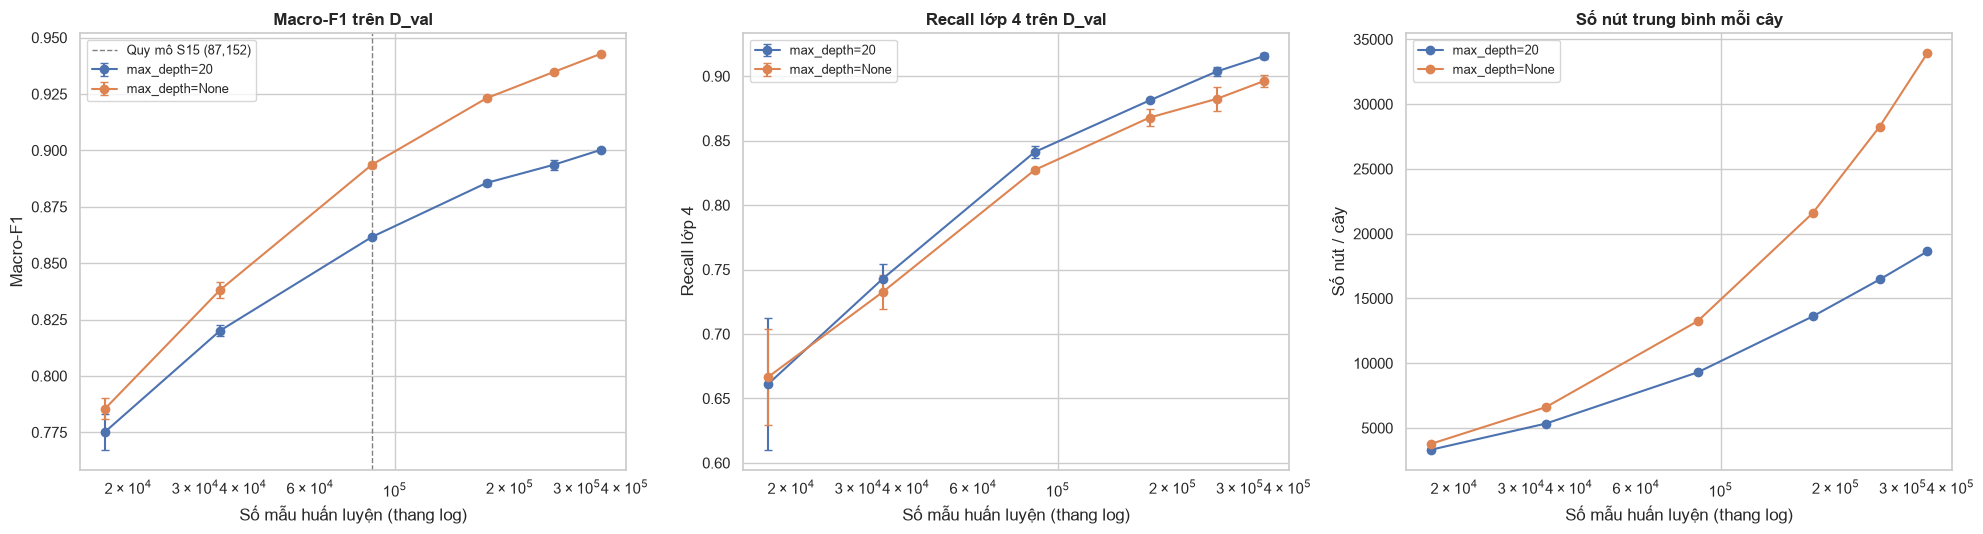

max_depth=20   : tốt nhất frac=1.00 (F1=0.9003 ± 0.0007); chọn frac=1.00 (F1=0.9003)
max_depth=None : tốt nhất frac=1.00 (F1=0.9429 ± 0.0002); chọn frac=1.00 (F1=0.9429)

→ Quy mô huấn luyện: 100% D_pool (n = 348,608); max_depth = None
  Chênh lệch Macro-F1 so với mức 25% D_pool (≈ S15), cùng max_depth: +0.0493


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for depth, grp in e4_sum.groupby('max_depth', sort=False):
    lbl = f"max_depth={depth}"
    axes[0].errorbar(grp['n_train'], grp['f1_mean'], yerr=grp['f1_sd'], marker='o', capsize=3, label=lbl)
    axes[1].errorbar(grp['n_train'], grp['rc4_mean'], yerr=grp['rc4_sd'], marker='o', capsize=3, label=lbl)
    axes[2].plot(grp['n_train'], grp['nodes'] / N_EST_EXP, marker='o', label=lbl)
axes[0].axvline(N_EXPLORE, color='gray', ls='--', lw=1, label=f'Quy mô S15 ({N_EXPLORE:,})')
for ax, title, ylab in zip(axes, ['Macro-F1 trên D_val', 'Recall lớp 4 trên D_val', 'Số nút trung bình mỗi cây'],
                           ['Macro-F1', 'Recall lớp 4', 'Số nút / cây']):
    ax.set_xscale('log')
    ax.set_xlabel('Số mẫu huấn luyện (thang log)')
    ax.set_ylabel(ylab)
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / 'e4_learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()

e4_choice = {}
for depth, grp in e4_sum.groupby('max_depth', sort=False):
    best = grp.loc[grp['f1_mean'].idxmax()]
    thr = best['f1_mean'] - best['f1_sd']
    e4_choice[depth] = grp[grp['f1_mean'] >= thr].sort_values('frac').iloc[0]
    print(f"max_depth={depth:<5}: tốt nhất frac={best['frac']:.2f} (F1={best['f1_mean']:.4f} ± {best['f1_sd']:.4f}); "
          f"chọn frac={e4_choice[depth]['frac']:.2f} (F1={e4_choice[depth]['f1_mean']:.4f})")
best_depth = max(e4_choice, key=lambda d: e4_choice[d]['f1_mean'])
TRAIN_FRAC = float(e4_choice[best_depth]['frac'])
MAX_DEPTH = None if best_depth == 'None' else int(best_depth)
idx_train = pool_subset_idx(TRAIN_FRAC, RANDOM_STATE)
X_tr, y_tr = X_pool.iloc[idx_train], y_pool.iloc[idx_train]
s15_ref = e4_sum[(e4_sum['frac'] == 0.25) & (e4_sum['max_depth'] == best_depth)]['f1_mean'].iloc[0]
print(f"\n→ Quy mô huấn luyện: {TRAIN_FRAC:.0%} D_pool (n = {len(y_tr):,}); max_depth = {MAX_DEPTH}")
print(f"  Chênh lệch Macro-F1 so với mức 25% D_pool (≈ S15), cùng max_depth: {e4_choice[best_depth]['f1_mean'] - s15_ref:+.4f}")

---
# BƯỚC 8: E5 — TINH CHỈNH SIÊU THAM SỐ
> Huấn luyện ở quy mô đã chọn ở E4, đánh giá trên D_val, `n_estimators = 100` (số cây được chốt riêng ở Bước 9).
> - **Giai đoạn 1**: `max_features` ∈ {sqrt, 0.35, 0.5, 0.7} × `criterion` ∈ {gini, entropy}; seed 42.
> - **Giai đoạn 2**: cấu hình tốt nhất giai đoạn 1 × `min_samples_leaf` ∈ {1, 2, 4} × `class_weight` ∈ {None, `balanced_subsample`, lựa chọn của E1}; seed 42.
> - **Giai đoạn 3**: 3 cấu hình đứng đầu, lặp đủ 3 seed.
>
> **Quy tắc chọn**: trong ngưỡng 1 SD, chọn cấu hình ít nút nhất, vì rừng nhỏ hơn dễ xấp xỉ bằng cây đại diện hơn và nhẹ hơn khi truy vấn.
>
> **Hạn chế**: tìm kiếm theo giai đoạn không quét mọi tổ hợp, nên có thể bỏ sót tương tác giữa các siêu tham số.

In [18]:
def run_cfg(cfg, seed, stage):
    r = fit_eval(X_tr, y_tr, X_val, y_val, {'n_estimators': N_EST_EXP, 'max_depth': MAX_DEPTH, **cfg}, seed)
    return {'stage': stage, 'cfg': json.dumps(cfg), **r}


e5_rows = []
for mf in ['sqrt', 0.35, 0.5, 0.7]:
    for crit in ['gini', 'entropy']:
        cfg = {'max_features': mf, 'criterion': crit, 'min_samples_leaf': 1, 'class_weight': CW}
        e5_rows.append(run_cfg(cfg, RANDOM_STATE, 1))
        r = e5_rows[-1]
        print(f"  [GĐ1] {r['cfg']}  F1={r['macro_f1']:.4f}  Rc4={r['recall_c4']:.4f}  nút={r['nodes']:,}  ({r['fit_s']:.0f}s)")
s1 = pd.DataFrame(e5_rows)
best_s1 = json.loads(s1.loc[s1['macro_f1'].idxmax(), 'cfg'])

cw_options = list(dict.fromkeys([None, 'balanced_subsample', CW]))
done = set(s1['cfg'])
for msl in [1, 2, 4]:
    for cw in cw_options:
        cfg = {**best_s1, 'min_samples_leaf': msl, 'class_weight': cw}
        if json.dumps(cfg) in done:
            continue
        e5_rows.append(run_cfg(cfg, RANDOM_STATE, 2))
        r = e5_rows[-1]
        print(f"  [GĐ2] {r['cfg']}  F1={r['macro_f1']:.4f}  Rc4={r['recall_c4']:.4f}  nút={r['nodes']:,}  ({r['fit_s']:.0f}s)")

top3 = pd.DataFrame(e5_rows).sort_values('macro_f1', ascending=False)['cfg'].drop_duplicates().head(3).tolist()
for cfg_s in top3:
    for seed in SEEDS[1:]:
        e5_rows.append(run_cfg(json.loads(cfg_s), seed, 3))
    print(f"  [GĐ3] đã lặp 3 seed: {cfg_s}")

e5_df = pd.DataFrame(e5_rows)
e5_df.to_csv(TABLE_DIR / 'e5_tuning.csv', index=False, encoding='utf-8-sig')
e5_top = summarize(e5_df[e5_df['cfg'].isin(top3)], 'cfg').sort_values('f1_mean', ascending=False)
display(e5_top)
show_per_class(e5_df[e5_df['cfg'].isin(top3)], 'cfg', 'E5 — 3 cấu hình đứng đầu')
e5_choice = choose_simplest(e5_top, 'cfg', 'nodes')
BEST_CFG = json.loads(e5_choice['cfg'])
FINAL_PARAMS = {'max_depth': MAX_DEPTH, **BEST_CFG}
print(f"\n→ Siêu tham số mô hình cuối: {FINAL_PARAMS}")

  [GĐ1] {"max_features": "sqrt", "criterion": "gini", "min_samples_leaf": 1, "class_weight": "balanced"}  F1=0.9427  Rc4=0.8945  nút=3,393,046  (12s)
  [GĐ1] {"max_features": "sqrt", "criterion": "entropy", "min_samples_leaf": 1, "class_weight": "balanced"}  F1=0.9438  Rc4=0.9036  nút=3,196,052  (12s)
  [GĐ1] {"max_features": 0.35, "criterion": "gini", "min_samples_leaf": 1, "class_weight": "balanced"}  F1=0.9430  Rc4=0.8927  nút=2,452,128  (20s)
  [GĐ1] {"max_features": 0.35, "criterion": "entropy", "min_samples_leaf": 1, "class_weight": "balanced"}  F1=0.9462  Rc4=0.8945  nút=2,225,920  (22s)
  [GĐ1] {"max_features": 0.5, "criterion": "gini", "min_samples_leaf": 1, "class_weight": "balanced"}  F1=0.9407  Rc4=0.8836  nút=2,290,626  (27s)
  [GĐ1] {"max_features": 0.5, "criterion": "entropy", "min_samples_leaf": 1, "class_weight": "balanced"}  F1=0.9450  Rc4=0.8964  nút=2,054,478  (29s)
  [GĐ1] {"max_features": 0.7, "criterion": "gini", "min_samples_leaf": 1, "class_weight": "balanced"}

,cfg,n_features,n_train,f1_mean,f1_sd,acc_mean,rc4_mean,rc4_sd,prec_c4,nodes,fit_s
0,"{""max_features"": 0.35, ""criterion"": ""entropy"",...",57,348608,0.9526,0.0008,0.9750,0.8903,0.0058,0.9198,2849811.3333,34.2891
1,"{""max_features"": 0.35, ""criterion"": ""entropy"",...",57,348608,0.9506,0.0006,0.9748,0.8848,0.0021,0.9165,3382067.3333,35.5123
2,"{""max_features"": 0.35, ""criterion"": ""entropy"",...",57,348608,0.9505,0.0005,0.9736,0.8879,0.0010,0.9208,2640092.6667,33.9312


--- F1 từng lớp (TB qua seed): E5 — 3 cấu hình đứng đầu ---


,L1,L2,L3,L4,L5,L6,L7,min
cfg,,,,,,,,
"{""max_features"": 0.35, ""criterion"": ""entropy"", ""min_samples_leaf"": 1, ""class_weight"": null}",0.9755,0.9795,0.9705,0.9048,0.9127,0.9525,0.9730,0.9048
"{""max_features"": 0.35, ""criterion"": ""entropy"", ""min_samples_leaf"": 1, ""class_weight"": ""balanced_subsample""}",0.9756,0.9794,0.9697,0.9004,0.9078,0.9496,0.9717,0.9004
"{""max_features"": 0.35, ""criterion"": ""entropy"", ""min_samples_leaf"": 2, ""class_weight"": null}",0.9741,0.9784,0.9690,0.9040,0.9081,0.9488,0.9709,0.9040


Tốt nhất theo F1: {"max_features": 0.35, "criterion": "entropy", "min_samples_leaf": 1, "class_weight": null} (0.9526 ± 0.0008) → ngưỡng 0.9518
Ứng viên trong ngưỡng: ['{"max_features": 0.35, "criterion": "entropy", "min_samples_leaf": 1, "class_weight": null}']
→ Chọn (ít nodes nhất): {"max_features": 0.35, "criterion": "entropy", "min_samples_leaf": 1, "class_weight": null}  (F1 = 0.9526 ± 0.0008)

→ Siêu tham số mô hình cuối: {'max_depth': None, 'max_features': 0.35, 'criterion': 'entropy', 'min_samples_leaf': 1, 'class_weight': None}


## 8.1. Ablation cột `Wilderness_Area` và tổ hợp khoảng cách (D_val)
> **Câu hỏi**: với siêu tham số đã chọn ở E5, hai nhóm đặc trưng có thể mã hoá vị trí ảnh hưởng thế nào tới Macro-F1 trên D_val? Mô hình đã bỏ 4 cột WA (đầu Bước 6), nên mục này **đưa cột WA trở lại** (`+ WA`) và bỏ 6 tổ hợp khoảng cách (`− tổ hợp KC`).
>
> **Thiết kế** (2×2: có/không WA × có/không 6 tổ hợp KC): cùng giao thức E5 (huấn luyện trên tập đã chọn ở E4, đánh giá trên D_val, `N_EST_EXP` cây, 3 seed). Mốc so sánh là các dòng E5 của cấu hình đã chọn. Siêu tham số giữ nguyên như mô hình cuối, tức đã được tinh chỉnh khi **không** có WA; điều này có thể bất lợi nhẹ cho các phương án `+ WA`.
>
> Mục này **không thay đổi** `FEATURE_SPEC`; nó cung cấp số đo kiểm chứng cho quyết định ở đầu Bước 6. D_final không được dùng.

In [19]:
WA_COLS = tuple(f'Wilderness_Area_{i}' for i in range(1, 5))
assert set(WA_COLS) <= set(FEATURE_SPEC.get('drop_raw', ())), 'mô hình cuối phải đã bỏ cột WA (Bước 6)'
_drop_wa = tuple(c for c in FEATURE_SPEC['drop_raw'] if c not in WA_COLS)   # đưa 4 cột WA trở lại
LOC_VARIANTS = {
    'Cuối + WA': {**FEATURE_SPEC, 'drop_raw': _drop_wa},
    'Cuối − tổ hợp KC': {**FEATURE_SPEC, 'dist_combo': False},
    'Cuối + WA − tổ hợp KC': {**FEATURE_SPEC, 'dist_combo': False, 'drop_raw': _drop_wa},
}
LOC_REF = 'Cuối (không WA, có tổ hợp KC)'

# (a) Chia ngẫu nhiên — mốc: các dòng E5 của cấu hình đã chọn (cùng giao thức)
loc_rows = [{'config': LOC_REF, **{k: v for k, v in r.items() if k not in ('stage', 'cfg')}}
            for r in e5_df[e5_df['cfg'] == json.dumps(BEST_CFG)].to_dict('records')]
assert len(loc_rows) == len(SEEDS), 'cấu hình đã chọn chưa đủ 3 seed trong E5'
X_tr_raw = X_pool_raw.loc[X_tr.index]
t0 = time.time()
for name, spec in LOC_VARIANTS.items():
    Xtr_v, Xval_v = build_features(X_tr_raw, **spec), build_features(X_val_raw, **spec)
    for seed in SEEDS:
        loc_rows.append({'config': name, **fit_eval(Xtr_v, y_tr, Xval_v, y_val,
                                                    {'n_estimators': N_EST_EXP, **FINAL_PARAMS}, seed)})
    print(f"  xong: {name} ({Xtr_v.shape[1]} cột) — {time.time() - t0:.0f}s")
    del Xtr_v, Xval_v
    gc.collect()

loc_df = pd.DataFrame(loc_rows)
loc_df.to_csv(TABLE_DIR / 'e5_location_ablation_val.csv', index=False, encoding='utf-8-sig')
loc_sum = summarize(loc_df, 'config')
loc_sum['ΔF1 so với Cuối'] = loc_sum['f1_mean'] - loc_sum.loc[loc_sum['config'] == LOC_REF, 'f1_mean'].iloc[0]
print("--- (a) Chia ngẫu nhiên, đánh giá trên D_val ---")
display(loc_sum[['config', 'n_features', 'f1_mean', 'f1_sd', 'ΔF1 so với Cuối', 'acc_mean', 'nodes']].round(4))
for m in ['precision', 'recall', 'f1']:
    print(f"--- {m.capitalize()} từng lớp (TB 3 seed) ---")
    display(per_class_table(loc_df, 'config', m).round(4))

  xong: Cuối + WA (61 cột) — 108s
  xong: Cuối − tổ hợp KC (51 cột) — 185s
  xong: Cuối + WA − tổ hợp KC (55 cột) — 264s
--- (a) Chia ngẫu nhiên, đánh giá trên D_val ---


,config,n_features,f1_mean,f1_sd,ΔF1 so với Cuối,acc_mean,nodes
0,"Cuối (không WA, có tổ hợp KC)",57,0.9526,0.0008,0.0000,0.9750,2849811.3333
1,Cuối + WA,61,0.9527,0.0008,0.0001,0.9754,2691938.0000
2,Cuối − tổ hợp KC,51,0.9416,0.0007,-0.0110,0.9667,3943083.3333
3,Cuối + WA − tổ hợp KC,55,0.9433,0.0002,-0.0093,0.9680,3667162.6667


--- Precision từng lớp (TB 3 seed) ---


,L1,L2,L3,L4,L5,L6,L7,min
config,,,,,,,,
"Cuối (không WA, có tổ hợp KC)",0.9787,0.9755,0.9665,0.9198,0.9434,0.9605,0.9793,0.9198
Cuối + WA,0.9790,0.9758,0.9671,0.9130,0.9418,0.9620,0.9804,0.9130
Cuối − tổ hợp KC,0.9723,0.9658,0.9593,0.9068,0.9298,0.9478,0.9743,0.9068
Cuối + WA − tổ hợp KC,0.9737,0.9670,0.9609,0.9009,0.9307,0.9513,0.9748,0.9009


--- Recall từng lớp (TB 3 seed) ---


,L1,L2,L3,L4,L5,L6,L7,min
config,,,,,,,,
"Cuối (không WA, có tổ hợp KC)",0.9723,0.9835,0.9746,0.8903,0.8839,0.9447,0.9668,0.8839
Cuối + WA,0.9727,0.9835,0.9752,0.8903,0.8836,0.9465,0.9692,0.8836
Cuối − tổ hợp KC,0.9611,0.9784,0.9673,0.8903,0.8463,0.9277,0.9603,0.8463
Cuối + WA − tổ hợp KC,0.9619,0.9795,0.9693,0.8873,0.8565,0.9355,0.9608,0.8565


--- F1 từng lớp (TB 3 seed) ---


,L1,L2,L3,L4,L5,L6,L7,min
config,,,,,,,,
"Cuối (không WA, có tổ hợp KC)",0.9755,0.9795,0.9705,0.9048,0.9127,0.9525,0.9730,0.9048
Cuối + WA,0.9758,0.9796,0.9712,0.9015,0.9117,0.9542,0.9748,0.9015
Cuối − tổ hợp KC,0.9666,0.9721,0.9633,0.8985,0.8861,0.9377,0.9672,0.8861
Cuối + WA − tổ hợp KC,0.9678,0.9732,0.9651,0.8940,0.8921,0.9433,0.9678,0.8921


## 8.2. Kiểm tra độ vững của lựa chọn E2/E3 dưới siêu tham số cuối (D_val)
> **Câu hỏi**: E2 và E3 chọn đặc trưng trên S15 với `class_weight='balanced'` và `max_features='sqrt'`, trong khi mô hình cuối dùng 100% D_pool, `class_weight=None`, `max_features=0.35`. Giả thuyết "pha loãng" của E3 lại phụ thuộc trực tiếp vào `max_features`. Lựa chọn có giữ nguyên khi đổi sang siêu tham số cuối không?
>
> **Thiết kế**: cùng giao thức mục 8.1 (huấn luyện trên tập đã chọn ở E4, D_val, `N_EST_EXP` cây, 3 seed). So sánh cấu hình cuối với ba phương án sát nút ở E2/E3: giữ cột `Aspect` + 3 cột `Hillshade` gốc; giữ `Hillshade_Noon`; thổ nhưỡng dạng `Soil_Type_Code`.
>
> **Quy ước đặt trước khi chạy**: mục này chỉ **báo cáo** kết quả của quy tắc 1 SD dưới siêu tham số cuối; `FEATURE_SPEC` **không đổi** dù kết quả thế nào, để các bước sau không phải chạy lại theo dây chuyền. Nếu quy tắc chọn một phương án khác, điều đó được ghi vào phần Hạn chế.

In [20]:
ROB_REF = 'Cuối (đặc trưng đã chọn)'
ROB_VARIANTS = {
    'Giữ Aspect + 3 Hillshade gốc': {**FEATURE_SPEC, 'drop_raw': tuple(c for c in FEATURE_SPEC['drop_raw']
                                                                  if c not in ASPECT_SHADE_RAW)},
    'Giữ Hillshade_Noon': {**FEATURE_SPEC, 'drop_raw': tuple(c for c in FEATURE_SPEC['drop_raw'] if c != 'Hillshade_Noon')},
    'Thổ nhưỡng dạng Code': {**FEATURE_SPEC, 'soil': 'code'},
}
rob_rows = [{'config': ROB_REF, **{k: v for k, v in r.items() if k not in ('stage', 'cfg')}}
            for r in e5_df[e5_df['cfg'] == json.dumps(BEST_CFG)].to_dict('records')]
assert len(rob_rows) == len(SEEDS), 'cấu hình đã chọn chưa đủ 3 seed trong E5'
X_tr_raw = X_pool_raw.loc[X_tr.index]
t0 = time.time()
for name, spec in ROB_VARIANTS.items():
    Xtr_v, Xval_v = build_features(X_tr_raw, **spec), build_features(X_val_raw, **spec)
    for seed in SEEDS:
        rob_rows.append({'config': name, **fit_eval(Xtr_v, y_tr, Xval_v, y_val,
                                                    {'n_estimators': N_EST_EXP, **FINAL_PARAMS}, seed)})
    print(f"  xong: {name} ({Xtr_v.shape[1]} cột) — {time.time() - t0:.0f}s")
    del Xtr_v, Xval_v
    gc.collect()

rob_df = pd.DataFrame(rob_rows)
rob_df.to_csv(TABLE_DIR / 'e5_feature_robustness_val.csv', index=False, encoding='utf-8-sig')
rob_sum = summarize(rob_df, 'config')
rob_sum['ΔF1 so với Cuối'] = rob_sum['f1_mean'] - rob_sum.loc[rob_sum['config'] == ROB_REF, 'f1_mean'].iloc[0]
display(rob_sum[['config', 'n_features', 'f1_mean', 'f1_sd', 'ΔF1 so với Cuối', 'acc_mean', 'rc4_mean', 'nodes']].round(4))
show_per_class(rob_df, 'config', '8.2')
rob_choice = choose_simplest(rob_sum, 'config', 'n_features')
if rob_choice['config'] == ROB_REF:
    print('\n→ Dưới siêu tham số cuối, quy tắc 1 SD vẫn chọn tập đặc trưng hiện tại.')
else:
    print(f"\n→ Dưới siêu tham số cuối, quy tắc 1 SD sẽ chọn '{rob_choice['config']}'. "
          "Theo quy ước đặt trước, FEATURE_SPEC không đổi; kết quả được ghi vào phần Hạn chế.")

  xong: Giữ Aspect + 3 Hillshade gốc (61 cột) — 121s
  xong: Giữ Hillshade_Noon (58 cột) — 232s
  xong: Thổ nhưỡng dạng Code (18 cột) — 314s


,config,n_features,f1_mean,f1_sd,ΔF1 so với Cuối,acc_mean,rc4_mean,nodes
0,Cuối (đặc trưng đã chọn),57,0.9526,0.0008,0.0000,0.9750,0.8903,2849811.3333
1,Giữ Aspect + 3 Hillshade gốc,61,0.9514,0.0017,-0.0012,0.9741,0.8855,2837472.0000
2,Giữ Hillshade_Noon,58,0.9527,0.0006,0.0000,0.9750,0.8891,2837710.0000
3,Thổ nhưỡng dạng Code,18,0.9521,0.0008,-0.0006,0.9748,0.8867,2847246.6667


--- F1 từng lớp (TB qua seed): 8.2 ---


,L1,L2,L3,L4,L5,L6,L7,min
config,,,,,,,,
Cuối (đặc trưng đã chọn),0.9755,0.9795,0.9705,0.9048,0.9127,0.9525,0.9730,0.9048
Giữ Aspect + 3 Hillshade gốc,0.9743,0.9786,0.9705,0.9019,0.9099,0.9524,0.9725,0.9019
Giữ Hillshade_Noon,0.9754,0.9794,0.9711,0.9044,0.9116,0.9536,0.9731,0.9044
Thổ nhưỡng dạng Code,0.9752,0.9793,0.9710,0.8992,0.9144,0.9527,0.9727,0.8992


Tốt nhất theo F1: Giữ Hillshade_Noon (0.9527 ± 0.0006) → ngưỡng 0.9520
Ứng viên trong ngưỡng: ['Thổ nhưỡng dạng Code', 'Cuối (đặc trưng đã chọn)', 'Giữ Hillshade_Noon']
→ Chọn (ít n_features nhất): Thổ nhưỡng dạng Code  (F1 = 0.9521 ± 0.0008)

→ Dưới siêu tham số cuối, quy tắc 1 SD sẽ chọn 'Thổ nhưỡng dạng Code'. Theo quy ước đặt trước, FEATURE_SPEC không đổi; kết quả được ghi vào phần Hạn chế.


---
# BƯỚC 9: MÔ HÌNH CUỐI — HUẤN LUYỆN, CHỐT SỐ CÂY, LƯU
> Huấn luyện tối đa 300 cây; số cây tối đa được hạ xuống nếu ước lượng bộ nhớ (từ số nút đo ở E5) vượt ngân sách 3 GB. Macro-F1 trên D_val được tính theo số cây k (trung bình xác suất của k cây đầu); chọn **k nhỏ nhất** có F1 ≥ F1(k_max) − 1 SD (SD lấy từ giai đoạn 3 của E5), rồi cắt mô hình còn k cây trước khi lưu.

In [21]:
nodes_per_tree = e5_choice['nodes'] / N_EST_EXP
n_est_budget = int(MEM_BUDGET_GB * 2**30 // (nodes_per_tree * BYTES_PER_NODE))
n_est_cap = max(100, (min(N_EST_MAX, n_est_budget) // 50) * 50)
if n_est_cap > n_est_budget:
    print(f"⚠ Mức sàn 100 cây vượt ngân sách {MEM_BUDGET_GB} GB (ngân sách chỉ đủ ≈ {n_est_budget} cây)")
print(f"≈ {nodes_per_tree:,.0f} nút/cây ≈ {nodes_per_tree * BYTES_PER_NODE / 2**20:.1f} MB/cây → tối đa {n_est_cap} cây")

t0 = time.time()
rf_final = RandomForestClassifier(n_estimators=n_est_cap, random_state=RANDOM_STATE, n_jobs=-1, **FINAL_PARAMS)
rf_final.fit(X_tr, y_tr)
print(f"Huấn luyện: {time.time() - t0:.0f}s, {n_nodes(rf_final):,} nút, RAM tiến trình {rss_gb():.2f} GB")

Xv = X_val.values
proba_cum = np.zeros((len(Xv), len(rf_final.classes_)))
k_grid = sorted({25, 50, 100, 150, 200, 250, 300, n_est_cap} & set(range(1, n_est_cap + 1)))
staged = []
for k, est in enumerate(rf_final.estimators_, start=1):
    proba_cum += est.predict_proba(Xv)
    if k in k_grid:
        y_k = rf_final.classes_[proba_cum.argmax(axis=1)]
        staged.append({'k': k, 'macro_f1': f1_score(y_val, y_k, average='macro'), 'accuracy': accuracy_score(y_val, y_k)})
staged_df = pd.DataFrame(staged)
display(staged_df)
f1_max = staged_df['macro_f1'].iloc[-1]
K_FINAL = int(staged_df[staged_df['macro_f1'] >= f1_max - e5_choice['f1_sd']]['k'].min())
print(f"F1({n_est_cap} cây) = {f1_max:.4f}; dung sai 1 SD = {e5_choice['f1_sd']:.4f} → giữ {K_FINAL} cây")
rf_final.estimators_ = rf_final.estimators_[:K_FINAL]
rf_final.n_estimators = K_FINAL
gc.collect()

MODEL_PATH = MODEL_DIR / 'rf_covertype_final.joblib'
joblib.dump(rf_final, MODEL_PATH, compress=3)
np.savez(MODEL_DIR / 'splits.npz', idx_final=X_final_raw.index.values, idx_val=X_val_raw.index.values,
         idx_train=X_tr.index.values)
FINAL_CONFIG = {'feature_spec': {**FEATURE_SPEC, 'eco': list(FEATURE_SPEC['eco'])}, 'features': FEATURES,
                'rf_params': {**FINAL_PARAMS, 'n_estimators': K_FINAL, 'random_state': RANDOM_STATE},
                'train_fraction_of_pool': TRAIN_FRAC, 'n_train': int(len(y_tr)),
                'surrogate_query_pool': 'idx_val (D_val)', 'final_eval_set': 'idx_final (D_final)'}
with open(MODEL_DIR / 'rf_final_config.json', 'w', encoding='utf-8') as f:
    json.dump(FINAL_CONFIG, f, ensure_ascii=False, indent=2)
print(f"✓ Đã lưu {MODEL_PATH.name} ({os.path.getsize(MODEL_PATH) / 2**20:.0f} MB), splits.npz, rf_final_config.json")
print(json.dumps(FINAL_CONFIG, ensure_ascii=False, indent=2))

≈ 28,498 nút/cây ≈ 3.3 MB/cây → tối đa 300 cây
Huấn luyện: 96s, 8,550,068 nút, RAM tiến trình 1.54 GB


,k,macro_f1,accuracy
0,25,0.9513,0.9734
1,50,0.9512,0.9743
2,100,0.9519,0.9750
3,150,0.9524,0.9753
4,200,0.9529,0.9755
5,250,0.9529,0.9753
6,300,0.9535,0.9753


F1(300 cây) = 0.9535; dung sai 1 SD = 0.0008 → giữ 200 cây
✓ Đã lưu rf_covertype_final.joblib (107 MB), splits.npz, rf_final_config.json
{
  "feature_spec": {
    "eco": [
      "D_Hydro",
      "Elevation_Water",
      "Aspect_Trig",
      "Delta_Hillshade"
    ],
    "dist_combo": true,
    "drop_raw": [
      "Aspect",
      "Hillshade_9am",
      "Hillshade_Noon",
      "Hillshade_3pm",
      "Wilderness_Area_1",
      "Wilderness_Area_2",
      "Wilderness_Area_3",
      "Wilderness_Area_4"
    ],
    "soil": "onehot"
  },
  "features": [
    "Elevation",
    "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Horizontal_Distance_To_Fire_Points",
    "Soil_Type_1",
    "Soil_Type_2",
    "Soil_Type_3",
    "Soil_Type_4",
    "Soil_Type_5",
    "Soil_Type_6",
    "Soil_Type_7",
    "Soil_Type_8",
    "Soil_Type_9",
    "Soil_Type_10",
    "Soil_Type_11",
    "Soil_Type_12",
    "Soil_Type_13",
    "Soil_

---
# BƯỚC 10: ĐÁNH GIÁ MỘT LẦN TRÊN D_final
> Đây là lần duy nhất D_final được dùng để báo cáo hiệu năng. Accuracy và Macro-F1 kèm KTC 95% bootstrap (1.000 lần); Recall từng lớp kèm khoảng Wilson 95%. Tầm quan trọng đặc trưng được tính trên một mẫu con phân tầng của D_val, để D_final chỉ phục vụ báo cáo hiệu năng.

## 10.1. Chỉ số tổng hợp, Classification Report, ma trận nhầm lẫn

D_final: n = 116,202 (lớp 4: 549)
  Accuracy: 0.9747  [KTC 95%: 0.9739–0.9756]
  Macro-F1: 0.9523  [KTC 95%: 0.9491–0.9558]


,n,Precision,Recall,F1
Lớp,,,,
Lớp 1 (Spruce/Fir),42368,0.9771 [0.9756–0.9786],0.9731 [0.9715–0.9746],0.9751 [0.9741–0.9761]
Lớp 2 (Lodgepole Pine),56660,0.9759 [0.9746–0.9771],0.9821 [0.9810–0.9832],0.9790 [0.9781–0.9798]
Lớp 3 (Ponderosa Pine),7151,0.9654 [0.9614–0.9696],0.9729 [0.9688–0.9764],0.9691 [0.9662–0.9718]
Lớp 4 (Cottonwood/Willow),549,0.9032 [0.8777–0.9259],0.8834 [0.8539–0.9076],0.8932 [0.8751–0.9110]
Lớp 5 (Aspen),1899,0.9541 [0.9445–0.9642],0.8984 [0.8840–0.9112],0.9254 [0.9173–0.9339]
Lớp 6 (Douglas-fir),3473,0.9634 [0.9571–0.9695],0.9395 [0.9311–0.9470],0.9513 [0.9461–0.9565]
Lớp 7 (Krummholz),4102,0.9774 [0.9727–0.9817],0.9690 [0.9633–0.9739],0.9732 [0.9698–0.9766]


                           precision    recall  f1-score   support

       Lớp 1 (Spruce/Fir)     0.9771    0.9731    0.9751     42368
   Lớp 2 (Lodgepole Pine)     0.9759    0.9821    0.9790     56660
   Lớp 3 (Ponderosa Pine)     0.9654    0.9729    0.9691      7151
Lớp 4 (Cottonwood/Willow)     0.9032    0.8834    0.8932       549
            Lớp 5 (Aspen)     0.9541    0.8984    0.9254      1899
      Lớp 6 (Douglas-fir)     0.9634    0.9395    0.9513      3473
        Lớp 7 (Krummholz)     0.9774    0.9690    0.9732      4102

                 accuracy                         0.9747    116202
                macro avg     0.9595    0.9455    0.9523    116202
             weighted avg     0.9747    0.9747    0.9746    116202



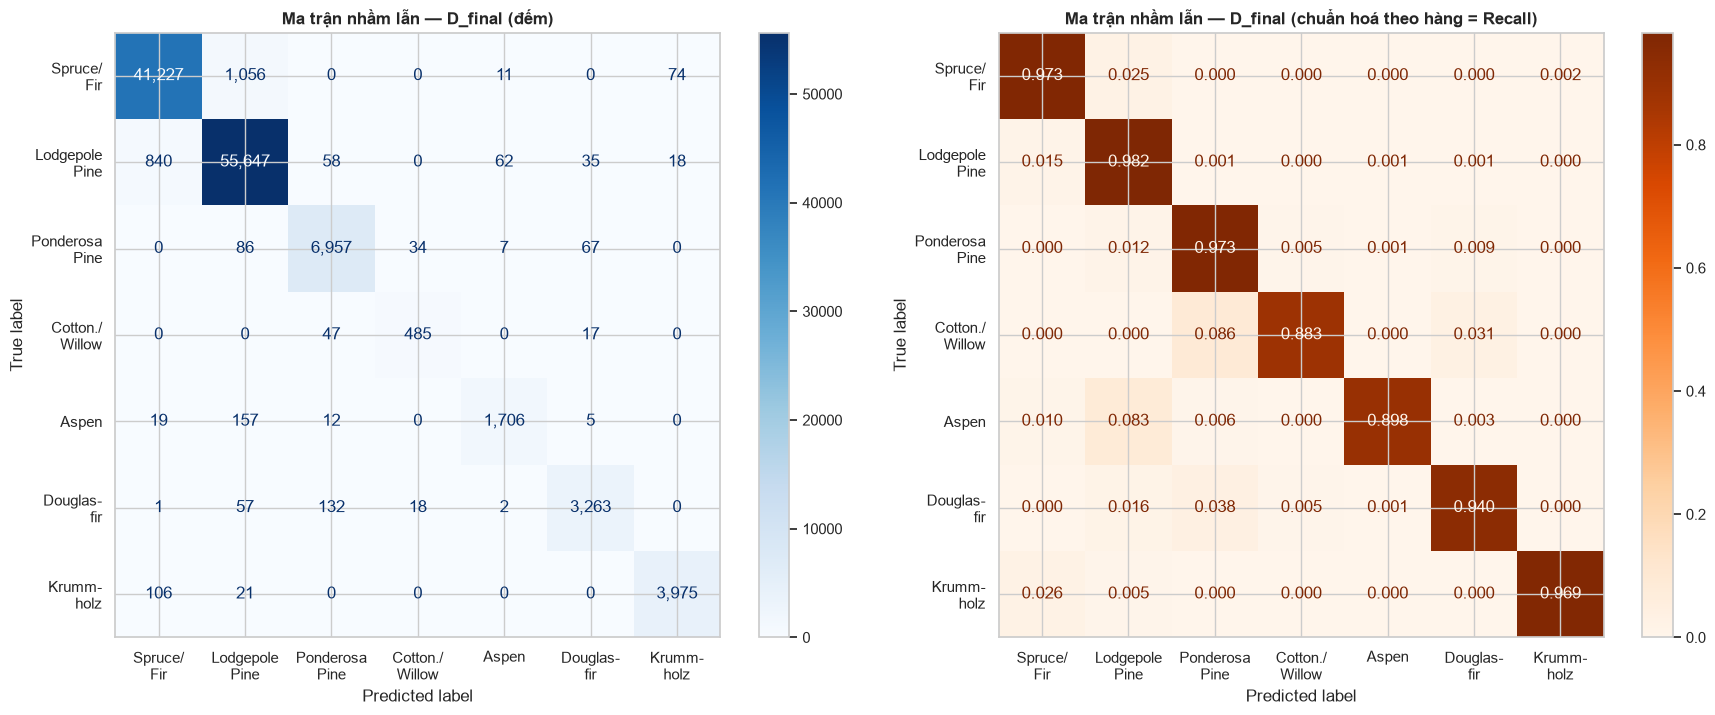

Lỗi chính của từng lớp:
  Lớp 1 (Spruce/Fir): Recall=0.973; nhầm nhiều nhất → Lớp 2 (Lodgepole Pine) (1,056 mẫu)
  Lớp 2 (Lodgepole Pine): Recall=0.982; nhầm nhiều nhất → Lớp 1 (Spruce/Fir) (840 mẫu)
  Lớp 3 (Ponderosa Pine): Recall=0.973; nhầm nhiều nhất → Lớp 2 (Lodgepole Pine) (86 mẫu)
  Lớp 4 (Cottonwood/Willow): Recall=0.883; nhầm nhiều nhất → Lớp 3 (Ponderosa Pine) (47 mẫu)
  Lớp 5 (Aspen): Recall=0.898; nhầm nhiều nhất → Lớp 2 (Lodgepole Pine) (157 mẫu)
  Lớp 6 (Douglas-fir): Recall=0.940; nhầm nhiều nhất → Lớp 3 (Ponderosa Pine) (132 mẫu)
  Lớp 7 (Krummholz): Recall=0.969; nhầm nhiều nhất → Lớp 1 (Spruce/Fir) (106 mẫu)


In [22]:
X_final = build_features(X_final_raw, **FEATURE_SPEC)
y_pred_final = rf_final.predict(X_final)
yf = y_final.values


def bootstrap_metrics(y_true, y_pred, n_boot=1000, seed=RANDOM_STATE):
    """Bootstrap theo dòng (n_boot lần) → mảng (n_boot × …) cho Accuracy, Macro-F1 và P/R/F1 từng lớp.
    Dùng ma trận nhầm lẫn qua np.bincount để mỗi lần lặp chỉ tốn O(n)."""
    rng = np.random.default_rng(seed)
    n, K = len(y_true), 7
    code_ = (y_true.astype(np.int64) - 1) * K + (y_pred.astype(np.int64) - 1)
    acc, mf1 = np.empty(n_boot), np.empty(n_boot)
    P, R, F = (np.empty((n_boot, K)) for _ in range(3))
    for b in range(n_boot):
        cm_b = np.bincount(code_[rng.integers(0, n, n)], minlength=K * K).reshape(K, K)
        tp = np.diag(cm_b).astype(float)
        with np.errstate(divide='ignore', invalid='ignore'):
            P[b] = np.nan_to_num(tp / cm_b.sum(axis=0))
            R[b] = np.nan_to_num(tp / cm_b.sum(axis=1))
            F[b] = np.nan_to_num(2 * P[b] * R[b] / (P[b] + R[b]))
        acc[b] = tp.sum() / n
        mf1[b] = F[b].mean()
    return acc, mf1, P, R, F


m_final = eval_preds(yf, y_pred_final)
b_acc, b_mf1, b_P, b_R, b_F = bootstrap_metrics(yf, y_pred_final)
ci = lambda a: np.percentile(a, [2.5, 97.5], axis=0)
ci_acc, ci_f1 = ci(b_acc), ci(b_mf1)
print(f"D_final: n = {len(yf):,} (lớp 4: {(yf == 4).sum():,})")
print(f"  Accuracy: {m_final['accuracy']:.4f}  [KTC 95%: {ci_acc[0]:.4f}–{ci_acc[1]:.4f}]")
print(f"  Macro-F1: {m_final['macro_f1']:.4f}  [KTC 95%: {ci_f1[0]:.4f}–{ci_f1[1]:.4f}]")

# --- Bảng 7 lớp: Precision / Recall / F1 kèm KTC 95% (Recall: Wilson; Precision, F1: bootstrap) ---
ciP, ciF = ci(b_P), ci(b_F)
rows = []
for c in range(1, 8):
    k, n = int(((yf == c) & (y_pred_final == c)).sum()), int((yf == c).sum())
    lo, hi = wilson_ci(k, n)
    rows.append({'Lớp': TARGET_NAMES[c - 1], 'n': n,
                 'Precision': f"{m_final[f'precision_c{c}']:.4f} [{ciP[0, c - 1]:.4f}–{ciP[1, c - 1]:.4f}]",
                 'Recall': f"{m_final[f'recall_c{c}']:.4f} [{lo:.4f}–{hi:.4f}]",
                 'F1': f"{m_final[f'f1_c{c}']:.4f} [{ciF[0, c - 1]:.4f}–{ciF[1, c - 1]:.4f}]"})
final_per_class = pd.DataFrame(rows).set_index('Lớp')
display(final_per_class)
final_per_class.to_csv(TABLE_DIR / 'final_per_class.csv', encoding='utf-8-sig')

print(classification_report(yf, y_pred_final, target_names=TARGET_NAMES, digits=4))

cm = confusion_matrix(yf, y_pred_final, labels=range(1, 8))
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ConfusionMatrixDisplay(cm, display_labels=SHORT_NAMES).plot(ax=axes[0], cmap='Blues', values_format=',')
axes[0].set_title('Ma trận nhầm lẫn — D_final (đếm)', fontweight='bold')
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=SHORT_NAMES).plot(
    ax=axes[1], cmap='Oranges', values_format='.3f')
axes[1].set_title('Ma trận nhầm lẫn — D_final (chuẩn hoá theo hàng = Recall)', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eval_confusion_final.png', dpi=150, bbox_inches='tight')
plt.show()

print("Lỗi chính của từng lớp:")
for i in range(7):
    errs = sorted([(cm[i, j], j) for j in range(7) if j != i], reverse=True)
    print(f"  {TARGET_NAMES[i]}: Recall={cm[i, i] / cm[i].sum():.3f}; nhầm nhiều nhất → "
          f"{TARGET_NAMES[errs[0][1]]} ({errs[0][0]:,} mẫu)")

## 10.2. Tầm quan trọng đặc trưng: MDI và Permutation (từng cột và theo nhóm)
> MDI (Mean Decrease Impurity) ở đây tính theo `criterion='entropy'` của mô hình cuối, không phải Gini. Permutation importance của các cột tương quan cao bị chia sẻ giữa chúng (ví dụ `Elevation` và `Elevation_Water`, r ≈ 0,98), nên ngoài hoán vị từng cột còn hoán vị **đồng thời** từng nhóm cột.

Permutation importance trên 20,000 mẫu D_val, 5 lần lặp (48s)


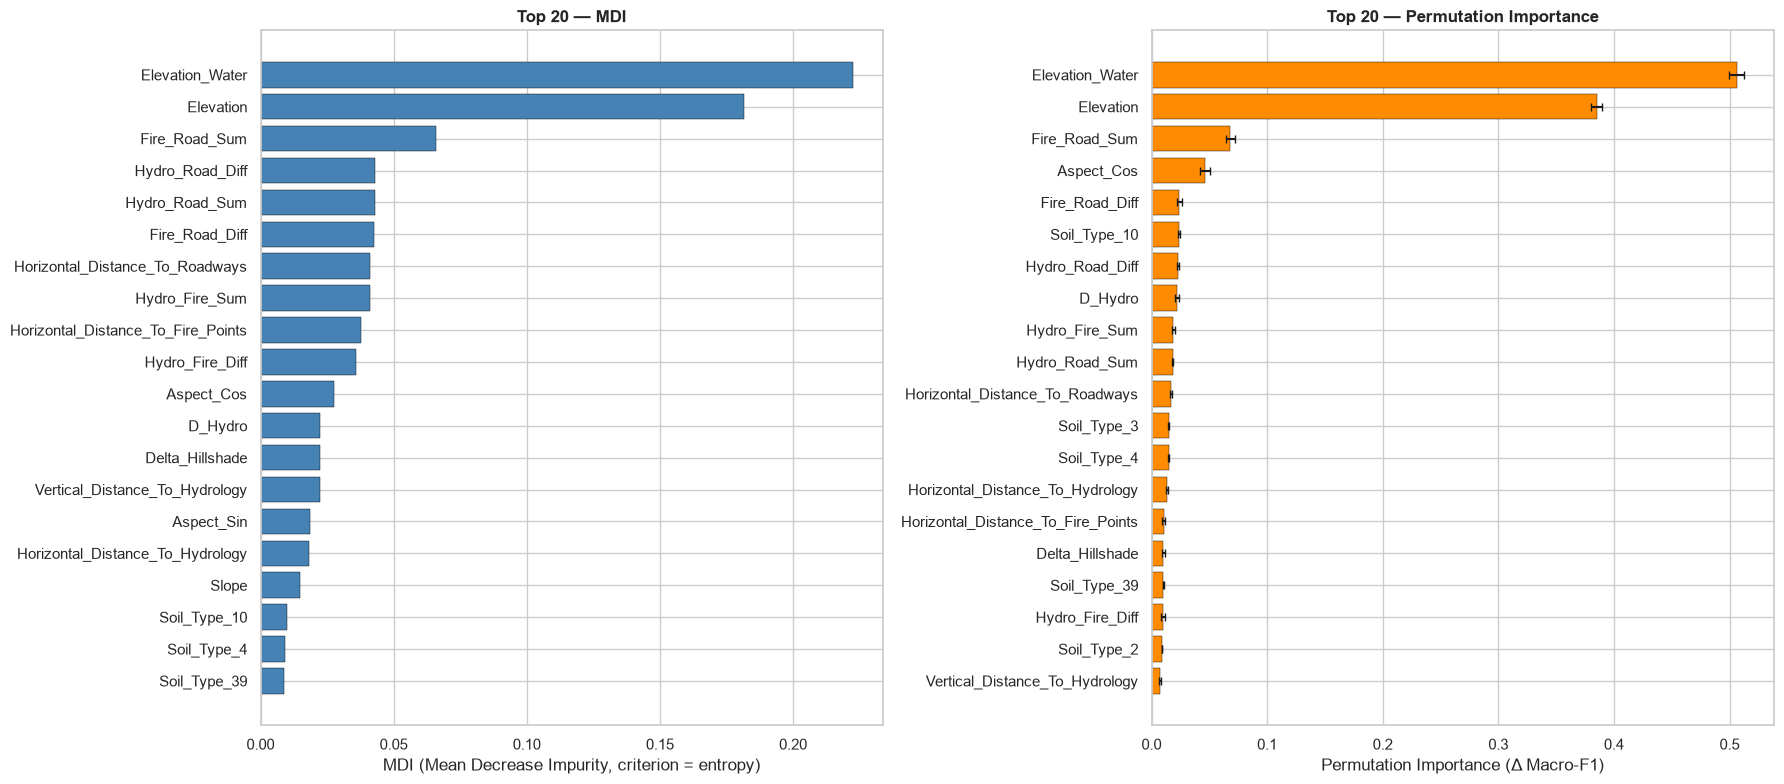

,mdi,perm_mean,perm_sd
Elevation_Water,0.2226,0.5060,0.0068
Elevation,0.1815,0.3850,0.0045
Fire_Road_Sum,0.0659,0.0681,0.0040
Aspect_Cos,0.0277,0.0460,0.0043
Fire_Road_Diff,0.0425,0.0238,0.0022
Soil_Type_10,0.0100,0.0236,0.0011
Hydro_Road_Diff,0.0429,0.0231,0.0011
D_Hydro,0.0225,0.0221,0.0015
Hydro_Fire_Sum,0.0410,0.0187,0.0014
Hydro_Road_Sum,0.0428,0.0184,0.0004


Lưu ý: MDI có xu hướng thiên về biến liên tục nhiều giá trị [15]; Permutation importance bị chia sẻ giữa các biến tương quan cao.
--- Permutation theo nhóm (Δ Macro-F1, 5 lần lặp; F1 gốc trên mẫu con = 0.9471) ---


,số cột,perm_nhóm_mean,perm_nhóm_sd,tổng perm từng cột
nhóm,,,,
"Cao độ (Elevation, Elevation_Water)",2,0.7228,0.0040,0.8910
Khoảng cách ngang + 6 tổ hợp,9,0.4843,0.0026,0.2029
Thổ nhưỡng (40 cột One-Hot),40,0.1415,0.0013,0.1154


In [23]:
idx_pi, _ = train_test_split(np.arange(len(y_val)), train_size=min(20000, len(y_val) - 7),
                             stratify=y_val, random_state=RANDOM_STATE)
t0 = time.time()
# n_jobs=1: với n_jobs > 1, joblib phải pickle cả rừng (hàng trăm MB) sang tiến trình con và có thể thất bại.
# Bản thân rf_final vẫn dự đoán song song (n_jobs=-1, luồng), nên tốc độ không giảm đáng kể.
perm = permutation_importance(rf_final, X_val.iloc[idx_pi], y_val.iloc[idx_pi], n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=1, scoring='f1_macro')
print(f"Permutation importance trên {len(idx_pi):,} mẫu D_val, 5 lần lặp ({time.time() - t0:.0f}s)")
imp = pd.DataFrame({'mdi': rf_final.feature_importances_, 'perm_mean': perm.importances_mean,
                    'perm_sd': perm.importances_std}, index=FEATURES).sort_values('perm_mean', ascending=False)
imp.to_csv(TABLE_DIR / 'feature_importance.csv', encoding='utf-8-sig')

top = min(20, len(imp))
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
g = imp.sort_values('mdi', ascending=False).head(top)
axes[0].barh(range(top), g['mdi'], color='steelblue', edgecolor='black', linewidth=0.3)
axes[0].set_yticks(range(top)); axes[0].set_yticklabels(g.index); axes[0].invert_yaxis()
axes[0].set_xlabel('MDI (Mean Decrease Impurity, criterion = entropy)')
axes[0].set_title(f'Top {top} — MDI', fontweight='bold')
p = imp.head(top)
axes[1].barh(range(top), p['perm_mean'], xerr=p['perm_sd'], color='darkorange', edgecolor='black',
             linewidth=0.3, capsize=3)
axes[1].set_yticks(range(top)); axes[1].set_yticklabels(p.index); axes[1].invert_yaxis()
axes[1].set_xlabel('Permutation Importance (Δ Macro-F1)')
axes[1].set_title(f'Top {top} — Permutation Importance', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eval_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
display(imp.head(15))
print("Lưu ý: MDI có xu hướng thiên về biến liên tục nhiều giá trị [15]; "
      "Permutation importance bị chia sẻ giữa các biến tương quan cao.")

# --- Permutation theo nhóm: hoán vị đồng thời các cột trong nhóm (cùng một hoán vị dòng) ---
DIST_COLS = ['Horizontal_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Horizontal_Distance_To_Fire_Points',
             'Hydro_Fire_Sum', 'Hydro_Fire_Diff', 'Hydro_Road_Sum', 'Hydro_Road_Diff', 'Fire_Road_Sum', 'Fire_Road_Diff']
PERM_GROUPS = {'Cao độ (Elevation, Elevation_Water)': ['Elevation', 'Elevation_Water'],
               'Khoảng cách ngang + 6 tổ hợp': DIST_COLS,
               'Thổ nhưỡng (40 cột One-Hot)': SOIL_COLS}
X_pi, y_pi = X_val.iloc[idx_pi], y_val.iloc[idx_pi].values
f1_base = f1_score(y_pi, rf_final.predict(X_pi), average='macro')
rng = np.random.default_rng(RANDOM_STATE)
grp_rows = []
for gname, cols in PERM_GROUPS.items():
    cols = [c for c in cols if c in FEATURES]
    drops = []
    for _ in range(5):
        X_perm = X_pi.copy()
        X_perm[cols] = X_pi[cols].values[rng.permutation(len(X_pi))]
        drops.append(f1_base - f1_score(y_pi, rf_final.predict(X_perm), average='macro'))
    grp_rows.append({'nhóm': gname, 'số cột': len(cols), 'perm_nhóm_mean': np.mean(drops), 'perm_nhóm_sd': np.std(drops),
                     'tổng perm từng cột': imp.loc[cols, 'perm_mean'].sum()})
grp_imp = pd.DataFrame(grp_rows).set_index('nhóm')
grp_imp.to_csv(TABLE_DIR / 'feature_importance_groups.csv', encoding='utf-8-sig')
print(f"--- Permutation theo nhóm (Δ Macro-F1, 5 lần lặp; F1 gốc trên mẫu con = {f1_base:.4f}) ---")
display(grp_imp.round(4))

---
# BƯỚC 11: TỔNG KẾT, HẠN CHẾ VÀ ĐẦU VÀO CHO BƯỚC TRÍCH XUẤT LUẬT
> Mọi số liệu dưới đây là **số đo thực nghiệm** của lần chạy này (seed 42, 7, 2024; scikit-learn 1.9.1), dạng TB ± SD qua 3 seed nếu không ghi khác. Mục 1–3 và 5 đo trên D_val, mục 4 trên D_final. Mọi chỉ số đều dùng phép chia ngẫu nhiên theo dòng, nên chỉ phản ánh dự đoán **bên trong 4 vùng nghiên cứu**.

## 1. Pha khảo sát trên S15 (E0–E3; 87.152 mẫu huấn luyện, 100 cây)
| Thí nghiệm | Kết quả chính (Macro-F1) | Quyết định |
| :--- | :--- | :--- |
| **E0/E1** — trọng số lớp (54 cột gốc) | `None` 0,8432 ± 0,0019; `balanced` 0,8471 ± 0,0012; `balanced_subsample` 0,8412 ± 0,0012. `balanced` nâng Recall lớp 5 từ 0,551 lên 0,791 nhưng Precision lớp 5 giảm từ 0,902 xuống 0,735; Precision lớp 4 giảm từ 0,836 xuống 0,818 | `balanced` (cho E2–E4) |
| **E2** — đặc trưng sinh thái (mọi phương án đã bỏ 4 cột `Wilderness_Area`, xem đầu Bước 6) | Gốc 50 cột 0,8444 ± 0,0006; + 4 nhóm sinh thái 0,8424 ± 0,0017 (không cải thiện). Bỏ `Elevation_Water`: −0,0151, nhóm có đóng góp lớn nhất. Thêm 6 tổ hợp khoảng cách: 0,8861 (+0,0436). Chỉ giữ dạng dẫn xuất của hướng sườn / bóng nắng (bỏ `Aspect` và 3 cột `Hillshade` gốc): **0,8927 ± 0,0011**; giữ thêm `Hillshade_Noon`: 0,8920 ± 0,0015; bỏ hẳn nhóm này: 0,8841 | Tổ hợp KC, chỉ dẫn xuất (57 cột) |
| **E3** — thổ nhưỡng | One-Hot 0,8927 ± 0,0011; Code 0,8907 ± 0,0009 (18 cột, ngay ngoài ngưỡng 1 SD); Code + Zone 0,8893; Zone 0,8860 | One-Hot |

- Khi chưa có tổ hợp khoảng cách, 4 nhóm đặc trưng sinh thái không cải thiện so với cột gốc; riêng `Aspect_Trig` và `Delta_Hillshade` lặp thông tin của cột gốc tương ứng (bỏ chúng cho F1 cao hơn, +0,0068 và +0,0056).
- Trên S15, bỏ 4 cột WA làm Macro-F1 giảm 0,0027 (E1 `balanced` 54 cột so với E2 "Gốc − WA" 50 cột). Mức chênh này không còn ở quy mô đầy đủ với siêu tham số cuối (mục 5).
- **Giả thuyết "pha loãng" của One-Hot** không được ủng hộ trong thiết lập này: gộp 40 cột đất thành mã số làm F1 giảm.

## 2. E4 — Quy mô dữ liệu (`class_weight='balanced'`)
- Với `max_depth=None`, Macro-F1 tăng từ 0,8936 ± 0,0014 (25% D_pool ≈ S15) lên **0,9429 ± 0,0002** (100% D_pool, 348.608 mẫu), tức +0,049. Đoạn 75% → 100% vẫn tăng +0,008: chưa quan sát thấy điểm bão hoà. Lớp hưởng lợi nhiều nhất là L5 (F1 0,833 → 0,898) và L6 (0,865 → 0,937).
- `max_depth=20` cho F1 thấp hơn ở mọi mức (ở 100%: 0,9003 ± 0,0007). Nó **dự đoán thừa lớp 5**: Recall lớp 5 0,970 nhưng Precision chỉ 0,628 (so với 0,947 / 0,853 khi không giới hạn độ sâu); Recall lớp 4 0,916 so với 0,896, Precision 0,877 so với 0,908.

## 3. E5 — Siêu tham số, số cây, mô hình cuối
- Giai đoạn 1 (`balanced`): `criterion='entropy'` cho F1 cao hơn `gini` ở cả 4 mức `max_features`; tốt nhất `max_features=0.35` + entropy (0,9462, 1 seed).
- Giai đoạn 2: `class_weight=None` cho F1 cao hơn `balanced` ở quy mô đầy đủ (0,9519 so với 0,9462, 1 seed), ngược với lựa chọn của E1 trên S15: lựa chọn trọng số lớp **phụ thuộc quy mô dữ liệu**. `class_weight` và `min_samples_leaf` chủ yếu dịch ngưỡng quyết định: ví dụ `balanced, min_samples_leaf=4` nâng Recall lớp 4 lên 0,929 (so với 0,884) nhưng Macro-F1 giảm 0,024 (1 seed; Precision/Recall từng lớp của mọi cấu hình ở `results/tables/e5_tuning.csv`).
- Giai đoạn 3 (3 seed): `min_samples_leaf=1, class_weight=None` **0,9526 ± 0,0008**; `min_samples_leaf=1, balanced_subsample` 0,9506 ± 0,0006; `min_samples_leaf=2, None` 0,9505 ± 0,0005. Quy tắc chọn cấu hình đầu.
- **Cấu hình cuối**: `max_depth=None, max_features=0.35, criterion='entropy', min_samples_leaf=1, class_weight=None`, 57 đặc trưng.
- **Số cây** (cắt dần từ một rừng 300 cây, 1 seed): F1 = 0,9513 (25 cây), 0,9519 (100), 0,9524 (150), 0,9529 (200), 0,9535 (300). Ngưỡng 0,9535 − 1 SD (0,0008) = 0,9527 → **200 cây** (≈ 28.500 nút/cây; file 107 MB; ở lần chạy này rừng 300 cây huấn luyện trong 96 s, RAM tiến trình 1,54 GB, hai số đo này phụ thuộc máy). Đường cong gần như phẳng từ 100 cây: mốc 150 hay 200 phụ thuộc vào một chênh lệch cỡ nhiễu (150 cây hụt ngưỡng 0,0003).

## 4. Đánh giá trên D_final (n = 116.202; lớp 4 = 549; KTC 95% bootstrap 1.000 lần)
| Chỉ số | Ngưỡng kỳ vọng (docs) | Số đo [KTC 95%] |
| :--- | :---: | :---: |
| Accuracy | ≥ 0,88 | 0,9747 [0,9739–0,9756] |
| Macro-F1 | ≥ 0,78 | 0,9523 [0,9491–0,9558] |
| Recall lớp 4 | ≥ 0,75 | 0,883 [0,854–0,908] |
| Recall lớp 5 (thấp thứ hai) | — | 0,898 [0,884–0,911] |

| Lớp | Precision | Recall | F1 |
| :--- | :---: | :---: | :---: |
| 1 Spruce/Fir | 0,977 | 0,973 | 0,975 |
| 2 Lodgepole Pine | 0,976 | 0,982 | 0,979 |
| 3 Ponderosa Pine | 0,965 | 0,973 | 0,969 |
| 4 Cottonwood/Willow | 0,903 [0,878–0,926] | 0,883 [0,854–0,908] | 0,893 [0,875–0,911] |
| 5 Aspen | 0,954 | 0,898 | 0,925 |
| 6 Douglas-fir | 0,963 | 0,940 | 0,951 |
| 7 Krummholz | 0,977 | 0,969 | 0,973 |

- Lỗi chủ yếu: lớp 1 ↔ 2 (1.056 và 840 mẫu; hai đai cao độ chồng lấn), 5 → 2 (157), 6 → 3 (132), 7 → 1 (106), 4 → 3 (47).
- **D_final đã được dùng 4 lần** (commit `3603bec`, lần chạy từng bước trước khi bỏ WA, commit `df3ce7f`, và lần chạy lại này với cùng cấu hình, cho số đo trùng khớp `df3ce7f`). Mọi lựa chọn đều dựa trên D_val; các chênh lệch giữa các phiên bản trên D_final đều nằm trong KTC và **không** được dùng để chọn phiên bản.
- **Tầm quan trọng (Permutation từng cột, 20.000 mẫu D_val, Δ Macro-F1)**: `Elevation_Water` 0,506, `Elevation` 0,385, `Fire_Road_Sum` 0,068, `Aspect_Cos` 0,046, `Fire_Road_Diff` 0,024, `Soil_Type_10` 0,024. MDI tính theo `criterion='entropy'`.
- **Permutation theo nhóm** (hoán vị đồng thời, 5 lần lặp; F1 gốc trên mẫu con 0,9471):

| Nhóm | Số cột | Δ Macro-F1 nhóm | Tổng Δ từng cột |
| :--- | :---: | :---: | :---: |
| Cao độ (`Elevation`, `Elevation_Water`) | 2 | 0,723 ± 0,004 | 0,891 |
| Khoảng cách ngang + 6 tổ hợp | 9 | 0,484 ± 0,003 | 0,203 |
| Thổ nhưỡng (40 cột One-Hot) | 40 | 0,142 ± 0,001 | 0,115 |

- Với nhóm khoảng cách và thổ nhưỡng, Δ của nhóm lớn hơn tổng Δ từng cột: thông tin được chia sẻ giữa các cột, nên hoán vị một cột đánh giá thấp vai trò của cả nhóm (ở nhóm khoảng cách, gấp khoảng 2,4 lần). Với nhóm cao độ thì ngược lại: tổng từng cột (0,891) lớn hơn Δ nhóm (0,723). `[GIẢ THUYẾT]` Hoán vị riêng một cột tạo ra tổ hợp không nhất quán giữa hai cột (tương đương một giá trị `Vertical_Distance_To_Hydrology` sai), nên làm giảm F1 thêm ngoài phần thông tin cao độ bị mất.

## 5. Ablation và kiểm tra độ vững dưới siêu tham số cuối (mục 8.1–8.2; D_val, 100 cây, 3 seed)
### 5.1. Cột `Wilderness_Area` và tổ hợp khoảng cách (mục 8.1)
| Phương án | Số cột | Macro-F1 | Δ so với Cuối |
| :--- | :---: | :---: | :---: |
| **Cuối** (không WA, có tổ hợp KC) | 57 | **0,9526 ± 0,0008** | — |
| Cuối + WA | 61 | 0,9527 ± 0,0008 | +0,0001 |
| Cuối − tổ hợp KC | 51 | 0,9416 ± 0,0007 | −0,0110 |
| Cuối + WA − tổ hợp KC | 55 | 0,9433 ± 0,0002 | −0,0093 |

- **Cột WA**: đưa trở lại không làm thay đổi Macro-F1 (chênh nhỏ hơn 1 SD), nhưng rừng có WA ít nút hơn (2,69 triệu so với 2,85 triệu), cho thấy mô hình có dùng WA như một đường tắt tới thông tin vị trí vốn đã có trong thổ nhưỡng, cao độ và khoảng cách. Theo quy tắc ra quyết định và lý do diễn giải (đầu Bước 6), mô hình cuối không dùng WA.
- **Tổ hợp khoảng cách**: bỏ chúng làm Macro-F1 giảm 0,011 (≈ 14 SD); L5 chịu thiệt nhiều nhất (F1 0,913 → 0,886). Mô hình cuối giữ 6 cột này.

### 5.2. Lựa chọn của E2/E3 (mục 8.2)
| Phương án | Số cột | Macro-F1 | Δ so với Cuối |
| :--- | :---: | :---: | :---: |
| **Cuối** (đặc trưng đã chọn) | 57 | 0,9526 ± 0,0008 | — |
| Giữ `Aspect` + 3 `Hillshade` gốc | 61 | 0,9514 ± 0,0017 | −0,0012 |
| Giữ `Hillshade_Noon` | 58 | 0,9527 ± 0,0006 | +0,0000 |
| Thổ nhưỡng dạng `Soil_Type_Code` | 18 | 0,9521 ± 0,0008 | −0,0006 |

- Các lựa chọn về hướng sườn / bóng nắng của E2 giữ nguyên: bỏ cột gốc vẫn không làm giảm F1.
- **Lựa chọn thổ nhưỡng của E3 không vững**: trên S15 (tham số E1), `Soil_Type_Code` thấp hơn One-Hot 0,0020, ngoài ngưỡng 1 SD. Dưới siêu tham số cuối, mức chênh còn 0,0006 và nằm trong ngưỡng (0,9520), nên quy tắc sẽ chọn `Soil_Type_Code` (18 cột). Theo quy ước đặt trước ở mục 8.2, `FEATURE_SPEC` giữ One-Hot.
- Giả thuyết "pha loãng" vẫn **không** được ủng hộ: ở cả hai thiết lập, One-Hot không thấp hơn `Soil_Type_Code`. Giả thuyết dự đoán bất lợi của One-Hot giảm khi `max_features` tăng (với 57 cột: từ √p ≈ 7 cột lên 0,35 p ≈ 19 cột); số đo cho thấy điều ngược lại về hướng, lợi thế của One-Hot thu hẹp từ 0,0020 xuống 0,0006. Mục 8.2 không tách riêng tác động của `max_features`, của quy mô dữ liệu và của `class_weight`, nên chưa kết luận được nguyên nhân của sự thu hẹp này.

## 6. Hạn chế
1. **Phạm vi áp dụng**: các chỉ số ở mục 1–5 chỉ đúng cho dự đoán bên trong 4 vùng nghiên cứu với phép chia ngẫu nhiên theo dòng. Các ô 30 m liền kề có thể nằm ở cả tập huấn luyện lẫn tập đánh giá (tự tương quan không gian), nên các chỉ số có thể lạc quan hơn so với khi áp dụng cho khu vực chưa khảo sát `[16]`. Dữ liệu không có toạ độ; notebook **không đánh giá** khả năng chuyển sang vùng mới.
2. KTC 95% trên D_final là bootstrap theo dòng: nó bỏ qua tương quan giữa các ô lân cận và không tính biến thiên do huấn luyện lại mô hình, nên có thể hẹp hơn mức bất định thực tế.
3. Độ lệch chuẩn qua seed phản ánh biến thiên do lấy mẫu con và do RF, **không** phản ánh biến thiên do chọn D_val (cố định). Ở E0–E3, S15 cố định qua các seed nên SD chỉ phản ánh phần ngẫu nhiên của RF; ngưỡng 1 SD vì vậy khá hẹp và gần như luôn chọn cấu hình có F1 cao nhất. D_val được dùng cho nhiều lựa chọn liên tiếp (E0–E5, số cây), nên số đo trên D_val có thể lạc quan nhẹ; Macro-F1 trên D_final (0,9523) gần với D_val (0,9526–0,9529).
4. **Quyết định bỏ cột WA** được đặt trước E2 và dựa trên lý do diễn giải; số đo ở quy mô đầy đủ (mục 5.1) cho thấy không khác biệt, nhưng trên S15 với tham số mặc định, bỏ WA làm giảm 0,0027.
5. Tìm kiếm tuần tự (E1 → E5) không quét đủ tương tác. Hai lựa chọn phụ thuộc vào siêu tham số: `class_weight` của E1 bị đảo ngược ở E5, và biểu diễn thổ nhưỡng của E3 sẽ đổi sang `Soil_Type_Code` nếu chọn lại dưới siêu tham số cuối (mục 5.2; chênh 0,0006). Mô hình cuối giữ One-Hot theo quy ước đặt trước. Nếu bước trích xuất luật cần ít cột hơn, `Soil_Type_Code` là phương án có hiệu năng tương đương trong phạm vi đo; nhược điểm là luật dạng `Soil_Type_Code ≤ c` coi mã đất như biến thứ bậc.
6. Cách diễn giải `Elevation_Water` là cao độ nguồn nước dựa trên **giả định** về quy ước dấu của `Vertical_Distance_To_Hydrology` (mục 3.3); hiệu năng của mô hình không phụ thuộc vào giả định này, nhưng ý nghĩa sinh thái của luật thì có.
7. Số cây (200) do quy tắc chọn dựa trên đường cong 1 seed và dung sai đo ở 100 cây; khác biệt với 150 cây nằm trong mức nhiễu.
8. Các tổ hợp khoảng cách là heuristic thực hành, chưa có cơ sở bình duyệt, gắn với vị trí (đường, điểm cháy) và vẫn có trong mô hình cuối. Nếu xuất hiện trong luật của cây đại diện, cần biện luận ý nghĩa sinh thái.
9. Rừng sâu (≈ 28.500 nút/cây, 200 cây) có thể khó xấp xỉ bằng một cây đại diện độ sâu 3–6: Fidelity `[CẦN ĐO]` ở E7.

## 7. Đầu vào cho bước trích xuất luật (E7)
- **Mô hình chủ**: `models/rf_covertype_final.joblib`; cấu hình và danh sách 57 đặc trưng ở `models/rf_final_config.json`; tái tạo đặc trưng bằng `build_features(df, **FEATURE_SPEC)`.
- **Chỉ số phân chia**: `models/splits.npz`. Dùng `idx_val` (D_val, rời tập huấn luyện RF) làm bể truy vấn để huấn luyện cây đại diện theo dự đoán của RF; dùng `idx_final` (D_final) để đo Fidelity và Accuracy của cây.
- Ngưỡng cao độ trong luật phản ánh phân bố gộp của 4 vùng, nên luật cần được trình bày là mô tả trong khu vực nghiên cứu, không phải quy luật áp dụng cho vùng khác.